# TP2 — Analyse Big Data des accidents de la route avec PySpark

*Reproduction de l'article [Big data Analysis of Road Crash Data using PySpark with PySpark Tutorial](https://medium.com/rakesh-nain/big-data-analysis-of-road-crash-data-using-pyspark-with-pyspark-tutorial-c78ff2c35588) (Rakesh Nain, 2021), puis analyse personnelle.*

Enzo Caramella — identifiant 24021136 — novembre 2026

## Ma contribution

### Le notebook est-il correct ?

**Oui.** Il s'exécute de bout en bout (*Restart & Run All*, ou `jupyter nbconvert --execute`), en environ 11 minutes
sur ma machine : Windows 11, 8 cœurs, 16 Go de RAM, PySpark 4.2.0, Java 21, Python 3.12. Les données sont téléchargées
automatiquement à la première exécution. Lors de l'exécution finale, 4 tâches Spark ont planté (workers Python sous
Windows, voir le point 4 ci-dessous) et ont été **recalculées automatiquement** grâce au réglage `local[*,4]`, sans
effet sur les résultats. Tous les résultats chiffrés publiés dans l'article sont retrouvés **à l'identique** (partitions, âges moyens, morts par type d'accident, tables de gravité, victimes des conducteurs sans
permis).

### Problèmes rencontrés

1. **Article inaccessible en lecture automatique** (Medium) : le code a été repris du notebook publié par l'auteur sur
   GitHub, et comparé au texte de l'article (même code, même ordre).
2. **Spark ne lit pas `dossier/*.csv` sous Windows** sans `winutils.exe` / `hadoop.dll`
   (`UnsatisfiedLinkError: NativeIO$Windows.access0`).
3. **`RDD.take()` et `first()` font « planter » le worker Python** sous Windows avec PySpark 4.x
   (`Python worker exited unexpectedly`). Le worker ferme la socket dès qu'il a assez de lignes, alors que la JVM écrit
   encore.
4. **Instabilité lors des premières exécutions complètes.** Une fois, le processus a été tué par manque de mémoire
   pendant `print_partitions`, qui rapatrie les 272 591 enregistrements sur le driver. Deux autres fois, des workers
   Python sont morts de façon **intermittente** pendant les jointures RDD (une fois la requête 1, une fois la
   requête 2), alors que ces cellules passaient seules. En mode local, Spark ne retente pas une tâche échouée, donc tout
   le job échouait.
5. **Bugs dans le code de l'article** (le code s'exécute, mais donne des résultats faux) :
   * `line.split(',')` coupe les champs qui contiennent une virgule entre guillemets, ce qui **décale 16,7 %** des
     lignes d'accidents (21 379 sur 127 672) ;
   * la requête RDD « Adélaïde » lit les mauvaises colonnes (index décalés d'un cran : âge au lieu du sexe, etc.) ;
   * la requête « victimes des conducteurs **sans** permis », en trois versions, sélectionne en réalité les conducteurs
     **avec** un permis connu, et ses trois versions ne donnent pas le même résultat (somme d'un côté, comptage de
     l'autre) ;
   * le chemin de `bank.csv` est faux (le fichier est dans `data for given tutorials/`), et l'article cite la colonne
     `Lic State` là où le code utilise `Veh Reg State`.

### Modifications apportées

Dans le code repris de l'article, chaque ligne modifiée porte un commentaire `# [MODIF]`.

* **Environnement** : `PYSPARK_PYTHON` pointe sur l'interpréteur du notebook. Sous Windows uniquement, `RDD.take()` est
  remplacé par une version qui consomme chaque partition en entier (même résultat).
* **Données** : téléchargement automatique dans `data/`. Spark reçoit la **liste explicite** des fichiers au lieu du
  motif `*.csv`, et `bank.csv` a un chemin corrigé.
* **Stabilité et mémoire** : `master = "local[*,4]"` au lieu de `local[*]` (mêmes 8 threads, mais jusqu'à 4 essais par
  tâche, comme sur un cluster : une tâche dont le worker meurt est recalculée à partir de la lignée du RDD).
  S'y ajoutent `spark.driver.memory = 2g` et `spark.python.worker.memory = 256m` (débordement sur disque plus tôt).
  `print_partitions` utilise `glom().map(len)`, qui ne rapatrie que les tailles des partitions (affichage identique).
* **Lisibilité** : les `collect()` de plusieurs milliers de lignes affichent le nombre de lignes et les 5 premières. Les
  avertissements Arrow sont masqués (PyArrow n'est pas installé).
* **Ajouts dans la Partie I** : un graphique lisible de la gravité selon l'alcool et les drogues, la même table calculée
  en une seule agrégation native (sans UDF ni jointure), et une **section 10 de corrections**. On y trouve un parsing
  CSV robuste, les bons index, et la bonne requête « sans permis ». Les trois API (RDD, DataFrame, SQL) y donnent
  désormais **exactement** les mêmes résultats, ce qui est vérifié dans le code.
* **Partie II (analyse personnelle)** : *qu'est-ce qui rend un accident grave ?* Elle comprend une table « un accident
  = une ligne » enrichie depuis les unités, une analyse exploratoire des facteurs de gravité (heure, jour, vitesse,
  usagers, conditions), et un pipeline Spark MLlib (régression logistique et forêt aléatoire pondérées) avec
  évaluation et interprétation.
* Chaque section est précédée d'une étiquette `## [Étape]` : Configuration, Data, EDA, Prétraitement, Transformation,
  ML, Éval, Conclusion.

### Autres informations

* L'article ne montre pas de sortie pour la requête 1 en RDD ni pour la requête 2 « trois API ». Les écarts relevés
  ici ne contredisent donc aucun résultat publié.
* L'analyse de la Partie II est **corrélationnelle** : les limites sont discutées dans la conclusion.
* Les graphiques sont enregistrés dans `figures/`. Le `README.md` du dossier résume le TP et indique comment le
  reproduire.

## Sommaire

**Partie I — Reproduction de l'article** *Big data Analysis of Road Crash Data using PySpark with PySpark Tutorial* (Rakesh Nain, Medium, 2021)

1. [Configuration] Environnement, imports, `SparkConf` et `SparkSession`
2. [Data] Téléchargement des données et création des RDD
3. [EDA] Premier contact avec les RDD (en-têtes, comptages, partitions)
4. [Transformation] Partitionnement personnalisé (`partitionBy`)
5. [EDA] Requêtes sur RDD (âge moyen, années des véhicules)
6. [Data] Création des DataFrames
7. [EDA] Requêtes sur DataFrame
8. [EDA] Gravité des accidents, alcool et drogues (+ graphiques)
9. [Transformation] Mêmes requêtes en RDD, DataFrame et SparkSQL
10. [Prétraitement] Corrections des bugs de l'article

**Partie II — Analyse personnelle : qu'est-ce qui rend un accident grave ?**

11. [Prétraitement] Construction d'une table « un accident = une ligne »
12. [EDA] Facteurs de gravité (heure, vitesse, usagers, conditions)
13. [Transformation] Pipeline de features Spark ML
14. [ML] Régression logistique et forêt aléatoire
15. [Éval] AUC, matrice de confusion, interprétation
16. [Conclusion]

# Partie I — Reproduction de l'article

Le code de l'article est repris **à l'identique** (commentaires anglais d'origine conservés). Les seules
différences sont marquées par un commentaire `# [MODIF]` et sont listées dans la première cellule.
Les corrections de fond (bugs de l'article) ne remplacent pas le code d'origine : elles sont ajoutées
**à côté**, dans la section 10, pour pouvoir comparer.

## [Configuration] Environnement, imports et session Spark

Deux réglages préalables, absents de l'article, sont nécessaires sur la machine de rendu (Windows 11) :

* **`PYSPARK_PYTHON`** : les workers Python lancés par Spark doivent utiliser le même interpréteur que le notebook
  (sinon Spark cherche un `python` global, ou un autre environnement sans les mêmes paquets).
* **`RDD.take()` sous Windows** : avec PySpark 4.x sous Windows, `take()` / `first()` font « planter » le worker Python
  (`Python worker exited unexpectedly (crashed)` / `Connection reset by peer`). Le worker arrête de lire sa partition
  dès qu'il a assez de lignes et ferme la socket alors que la JVM écrit encore. La JVM interprète cette fermeture comme
  un crash. Le correctif ci-dessous remplace `take()` par une version qui lit la partition jusqu'au bout avant de
  rendre les `n` premiers éléments. Le résultat est identique, et le correctif n'est appliqué que sous Windows.

In [1]:
# [MODIF] Réglages d'environnement (absents de l'article, nécessaires sous Windows)
import os, sys, glob, time, warnings
warnings.filterwarnings("ignore", category=FutureWarning)  # avertissement « pandas >= 3 » de PySpark, sans effet ici
warnings.filterwarnings("ignore", message=".*Arrow")        # PyArrow non installé : Spark repasse seul en mode sans Arrow
os.environ["PYSPARK_PYTHON"] = sys.executable          # workers Python = même interpréteur que le notebook
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

from itertools import islice
from pyspark.rdd import RDD

if os.name == "nt":
    def _take_partition_complete(self, num):
        """Équivalent de RDD.take(num) qui consomme chaque partition en entier (contournement Windows)."""
        def tete(iterateur):
            premiers = list(islice(iterateur, num))
            for _ in iterateur:   # on vide le reste : le worker ne ferme plus la socket trop tôt
                pass
            return premiers
        return self.mapPartitions(tete).collect()[:num]
    RDD.take = _take_partition_complete      # RDD.first() appelle take(1) : il est couvert aussi

T0_NOTEBOOK = time.perf_counter()

### Imports de l'article

> *What is PySpark?* PySpark est l'API Python d'Apache Spark, un framework de calcul distribué généraliste.
> Spark parallélise implicitement les traitements et tolère les pannes. Côté Python, c'est un simple module à importer.

In [2]:
from pyspark import SparkConf
from pyspark import SparkContext
from pyspark.sql import SparkSession
from pyspark.sql.functions import udf
from pyspark.sql.types import IntegerType
from pyspark.sql.types import LongType
from pyspark.sql.types import FloatType
from pyspark.rdd import RDD
from pyspark.sql.types import StringType
from pyspark.sql.functions import col
import pyspark.sql.functions as F
import csv
from datetime import datetime
from functools import reduce
import pandas as pd
import matplotlib.pyplot as plt

### Calcul parallèle vs calcul distribué

Comme dans l'article, Spark tourne ici en **mode local** : le calcul est *parallèle* (plusieurs cœurs d'une même
machine), pas *distribué* (plusieurs machines). Le code serait identique sur un cluster : seul le `master` changerait
(`spark://…`, `yarn`, `k8s://…`).

### Configuration de PySpark (`SparkConf`)

In [3]:
# local[*]: run Spark in local-mode(parallel computing) with as many working processors as logical cores on your machine
# If we want Spark to run locally with 'k' worker threads, we can specify as "local[k]".
master = "local[*]"
# [MODIF] local[*,4] : mêmes 8 threads, mais chaque tâche peut être retentée jusqu'à 4 fois (1 seule par défaut en local)
master = "local[*,4]"

# The `appName` field is a name to be shown on the Spark cluster UI page
app_name = "Big data Analysis of Road Crash Data"

# Setup configuration parameters for Spark
spark_conf = SparkConf().setMaster(master).setAppName(app_name)
# [MODIF] Réglages mémoire (voir la note ci-dessous)
spark_conf = (spark_conf
              .set("spark.driver.memory", "2g")           # JVM : 2 Go (défaut 1 Go), suffisant pour la partie ML
              .set("spark.python.worker.memory", "256m"))  # chaque worker Python déborde sur disque au-delà de 256 Mo

> **Note sur la stabilité (Windows).** Mes premières exécutions complètes ont échoué de deux façons :
>
> 1. **Manque de mémoire** : une fois, le processus a été tué pendant `print_partitions`, qui rapatriait 272 591
>    enregistrements sur le driver (corrigé plus bas avec `glom().map(len)`).
> 2. **Workers Python qui meurent pendant les jointures RDD** (`Python worker exited unexpectedly (crashed)` /
>    `connexion abandonnée par un logiciel de votre ordinateur hôte`), de façon **intermittente**. Une fois sur la
>    requête 2 de la section 9, une autre fois sur la requête 1, alors que ces mêmes cellules passaient seules plusieurs
>    fois de suite. Sous Windows, Spark lance un nouveau processus `python.exe` par tâche (pas de démon comme sous
>    Linux) : 8 à la fois, qui font chacun leur part de la jointure en mémoire. Je n'ai pas pu établir la cause exacte
>    (pression mémoire, ou socket coupée côté système).
>
> Deux réglages, sans effet sur les résultats :
>
> * **`local[*,4]`** au lieu de `local[*]`. En mode local, Spark ne fait par défaut **qu'un seul essai** par tâche :
>   la moindre défaillance fait échouer tout le job. Le second nombre autorise jusqu'à 4 essais, comme sur un cluster.
>   Une tâche dont le worker meurt est simplement **recalculée**, à partir de la lignée du RDD : c'est le « R » de RDD
>   (*Resilient*).
> * **`spark.python.worker.memory = 256m`** (512 Mo par défaut) : chaque worker déborde sur disque plus tôt pendant les
>   `join` et les `groupByKey`, ce qui limite la mémoire totale consommée par les 8 workers.

### Création de la `SparkSession`

La `SparkSession` est le point d'entrée unique (DataFrames, SQL). Elle contient le `SparkContext` (`sc`), qui sert à créer
les RDD.

In [4]:
# creating a SparkContext object
spark = SparkSession.builder.config(conf=spark_conf).getOrCreate()
sc = spark.sparkContext
sc.setLogLevel('ERROR')

# [MODIF] affichage de l'environnement d'exécution
print("Spark   :", spark.version)
print("Python  :", sys.version.split()[0])
print("Java    :", sc._jvm.java.lang.System.getProperty("java.version"))
print("Master  :", sc.master, "->", sc.defaultParallelism, "tâches en parallèle")

Spark   : 4.2.0
Python  : 3.12.15
Java    : 21.0.12.1
Master  : local[*,4] -> 8 tâches en parallèle


## [Data] Téléchargement des données et création des RDD

**Jeu de données** : *Road Crash Data* 2012–2019 de l'Australie-Méridionale, publié par le Department of Planning,
Transport and Infrastructure (DPTI) sur [data.sa.gov.au](https://data.sa.gov.au). Seuls deux jeux sont utilisés :

| Jeu | Grain | Contenu |
|---|---|---|
| **Crash** (`crash_data/`) | 1 ligne = 1 accident | lieu, date (année, mois, **jour de la semaine**), heure, vitesse autorisée, météo, type d'accident, gravité (`CSEF Severity`), alcool (`DUI Involved`), drogues (`Drugs Involved`)… |
| **Units** (`units_data/`) | 1 ligne = 1 « unité » impliquée | véhicule, piéton, arbre… avec type, année du véhicule, sexe/âge du conducteur, permis… |

Les deux tables se joignent sur `REPORT_ID`. Le jour exact n'est pas publié (donnée sensible) : une date s'écrit donc
`Année-Mois-JourDeLaSemaine`, par exemple `2017-January-Sunday`.

Comme le recommande l'article, les fichiers sont pris sur le [dépôt GitHub de l'auteur](https://github.com/RakeshNain/Big-data-Analysis-of-Road-Crash-Data-using-PySpark-with-PySpark-Tutorial).
**[MODIF]** La cellule suivante les télécharge automatiquement dans `./data/` s'ils sont absents (~85 Mo, ignorés par git).

In [5]:
# [MODIF] Téléchargement automatique des données (l'article suppose un téléchargement manuel)
import urllib.request, urllib.parse

DEPOT = ("https://raw.githubusercontent.com/RakeshNain/"
         "Big-data-Analysis-of-Road-Crash-Data-using-PySpark-with-PySpark-Tutorial/main/")
DATA_DIR = "data"
ANNEES = range(2012, 2020)
A_TELECHARGER = (
    [(f"crash_data/{a}_DATA_SA_Crash.csv", f"crash_data/{a}_DATA_SA_Crash.csv") for a in ANNEES]
    + [(f"units_data/{a}_DATA_SA_Units.csv", f"units_data/{a}_DATA_SA_Units.csv") for a in ANNEES]
    + [("data for given tutorials/bank.csv", "bank.csv"),          # utilisé par l'exemple spark.read.csv de l'article
       ("metadata-for-road-crash.pdf", "metadata-for-road-crash.pdf")]
)

for source, cible in A_TELECHARGER:
    chemin = os.path.join(DATA_DIR, cible)
    if not os.path.exists(chemin):
        os.makedirs(os.path.dirname(chemin), exist_ok=True)
        urllib.request.urlretrieve(DEPOT + urllib.parse.quote(source), chemin)

def fichiers(dossier):
    """Liste explicite des CSV d'un dossier de données.

    [MODIF] L'article lit './units_data/*.csv'. Sous Windows, sans winutils.exe/hadoop.dll, Hadoop ne sait pas lister
    un dossier (UnsatisfiedLinkError NativeIO$Windows.access0). On donne donc à Spark la liste des fichiers,
    construite en Python : le résultat est identique sur toutes les plateformes.
    """
    return sorted(glob.glob(os.path.join(DATA_DIR, dossier, "*.csv")))

for d in ("crash_data", "units_data"):
    tailles = [os.path.getsize(f) for f in fichiers(d)]
    print(f"{d:<11}: {len(tailles)} fichiers, {sum(tailles) / 1e6:.1f} Mo")

crash_data : 8 fichiers, 42.5 Mo
units_data : 8 fichiers, 37.7 Mo


### Les RDD

Un **RDD** (*Resilient Distributed Dataset*) est l'abstraction de base de Spark : une collection d'objets **immuable**,
découpée en **partitions** traitées en parallèle. On le manipule par des **transformations** paresseuses (`map`,
`filter`, `join`…), qui créent de nouveaux RDD, et par des **actions** (`collect`, `count`, `take`…), qui déclenchent
le calcul.

Le `SparkContext` offre deux façons de créer un RDD :

* `parallelize()` distribue une collection Python (`list`, `tuple`, `set`) ;
* `textFile()` lit un fichier texte : **un élément du RDD = une ligne** (une chaîne à découper ensuite avec `map`).

In [6]:
## FROM A LIST
# By default the number of partitions will be the number of threads
data_list = [i for i in range(10)]
#print(data_list)
rdd = sc.parallelize(data_list)
# You can verify the number of partitions of the data
print('Default partitions: ',rdd.getNumPartitions())
# the function parallelize can have a second argument to indicate manually how many
# partitions for the data
rdd = sc.parallelize(data_list,5)
# Verify the new number of partitions of the data
print('Manual partitions: ',rdd.getNumPartitions())
# Show the data by performing the action *collect*
rdd.collect()

Default partitions:  8
Manual partitions:  5


[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

Par défaut, `parallelize` crée autant de partitions que de threads disponibles (`local[*]`, donc le nombre de cœurs
logiques). Avec 5 partitions demandées, on en obtient bien 5. Chargement des CSV avec `textFile()` :

In [7]:
# Importing all the "Units" csv files from downloaded 2012–2019 South Australia Road Crash Data into a single RDD.
# creating RDD object by reading csv file
units_rdd = sc.textFile(",".join(fichiers('units_data')))   # [MODIF] liste explicite au lieu de './units_data/*.csv'

# Importing all the "Crashes" csv files from 2012–2019 into a single RDD.
# creating RDD object by reading csv file
crash_rdd = sc.textFile(",".join(fichiers('crash_data')))   # [MODIF] liste explicite au lieu de './crash_data/*.csv'

## [EDA] Premier contact avec les RDD

Pour chaque RDD, on retire la ligne d'en-tête, puis on affiche le nombre total d'enregistrements et les 10 premiers.
Tous les fichiers annuels ont le même en-tête : un seul `filter` supprime les 8 occurrences.

In [8]:
# Removing the header of units_rdd
units_header = units_rdd.first()
units_rdd = units_rdd.filter(lambda row: row != units_header)   #filter out header
print("Total count of units_rdd: ", units_rdd.count())
print(units_rdd.take(10))

Total count of units_rdd:  272591


['"2012-1-21/08/2019","01",0,,"Pedal Cycle",,"South West","Male","035",,,,,"Straight Ahead","001","5074",,', '"2012-1-21/08/2019","02",0,"SA","Motor Cars - Sedan","2009","North West","Female","050","SA","C ","Full","Unknown","Leaving Private Driveway","001","5089",,', '"2012-2-21/08/2019","01",0,"SA","Motor Cars - Sedan","1999","West","Male","027","SA",,"Provisional 1 ","Not Towing","Straight Ahead","002","5008",,', '"2012-2-21/08/2019","02",0,"SA","Motor Cars - Sedan","1993","West",,,,,,"Not Towing","Parked","000",,,', '"2012-3-21/08/2019","01",0,"SA","Motor Cars - Sedan","XXXX","North East","Male","050","SA",,"Full","Trailer","Straight Ahead","006","5107",,', '"2012-3-21/08/2019","02",0,"SA","Motor Cars - Sedan","2006","North East","Male","044","SA",,"Full","Not Towing","Straight Ahead","003","5092",,', '"2012-3-21/08/2019","03",0,,"Other Inanimate Object",,,,,,,,,,,,,', '"2012-4-21/08/2019","01",0,"SA","Station Wagon","2009","South West","Female","037","SA",,"Full","Not Towing","Sto

In [9]:
# Removing the header of crash_rdd
crash_header = crash_rdd.first()
crash_rdd = crash_rdd.filter(lambda row: row != crash_header)   #filter out header
print("Total count of crash_rdd: ", crash_rdd.count())
print(crash_rdd.take(10))

Total count of crash_rdd:  127672


['"2012-1-21/08/2019","2 Metropolitan","STEPNEY","5069","CC OF NORWOOD,PAYNEHAM & ST PETERS",2,0,0,0,0,2012,"January","Sunday","04:30 pm","060","Not Divided","Straight road","Level","Driveway or Entrance","Sealed","Dry","Not Raining","Daylight","Right Angle","02","Driver Rider","1: PDO","No Control","","",1330659.71,1671795.87,"13306601671796"', '"2012-2-21/08/2019","2 Metropolitan","PARKSIDE","5063","CITY OF UNLEY",2,0,0,0,0,2012,"January","Sunday","09:10 am","040","Not Divided","Straight road","Level","Not Applicable","Sealed","Dry","Not Raining","Daylight","Hit Parked Vehicle","01","Driver Rider","1: PDO","No Control","","",1329400.16,1668462.66,"13294001668463"', '"2012-3-21/08/2019","2 Metropolitan","SELLICKS BEACH","5174","CITY OF ONKAPARINGA",3,0,0,0,0,2012,"January","Wednesday","11:30 am","100","Not Divided","Straight road","Slope","Not Applicable","Sealed","Dry","Not Raining","Daylight","Other","01","Driver Rider","1: PDO","No Control","","",1313748.22,1624241.28,"131374816242

**127 672 accidents** et **272 591 unités** sur 8 ans : environ 2,1 unités par accident. Les lignes sont encore des
chaînes CSV brutes. Point important pour la suite : certains champs entre guillemets contiennent des virgules
(par exemple `"CC OF NORWOOD,PAYNEHAM & ST PETERS"` dans `LGA Name`). Un simple `split(',')` les coupera en deux
(voir section 10).

Sans stratégie de partitionnement explicite, Spark découpe les fichiers en blocs de taille à peu près égale (*random
equal partitioning*) :

In [10]:
print("Units Data:")
print(f"Total partitions: {units_rdd.getNumPartitions()}")
print("Crash Data:")
print(f"Total partitions: {crash_rdd.getNumPartitions()}")

Units Data:
Total partitions: 8
Crash Data:
Total partitions: 8


8 partitions pour chaque RDD, comme dans l'article : une partition par fichier annuel, car chaque fichier (< 8 Mo)
est plus petit qu'un bloc Hadoop (32 Mo en local).

## [Transformation] Partitionnement personnalisé

On peut aussi choisir soi-même le partitionnement. Exemple de l'article : deux partitions, une pour les véhicules
immatriculés en Australie-Méridionale (`SA`), l'autre pour tous les autres. On crée d'abord un **RDD clé-valeur**
`(état, autres colonnes)`.

> L'article parle de la colonne `Lic State`, mais l'index 3 utilisé par le code correspond à **`Veh Reg State`**
> (état d'immatriculation du véhicule). C'est d'ailleurs ce que décrit le texte (« *the state where the vehicle is
> registered* ») : le code est juste, seul le nom de colonne cité est faux.

In [11]:
# define a function which will be applied to each rdd element
def parseRecord(line):
    lines = line.split(',')
    array_line = []
    for value in lines:
        array_line.append(str(value).replace('"', ''))
    return (array_line[3], [x for i,x in enumerate(array_line) if i!=3] )
units_state_rdd = units_rdd.map(parseRecord)

`partitionBy(nombre, fonction)` place chaque paire dans la partition renvoyée par la fonction appliquée à la clé :

In [12]:
# define function to partition data into two parts, one only for SA state and other one for alll the states
def hash_SA(key):
    if key == 'SA':
        return 0
    else:
        return 1

SA_partitioned_rdd = units_state_rdd.partitionBy(2, hash_SA)

In [13]:
#A Function to print the number of elements in each partion of the given rdd
def print_partitions(data):
    if isinstance(data, RDD):
        numPartitions = data.getNumPartitions()
        partitions = data.glom().map(len).collect()       # [MODIF] .map(len) : on ne rapatrie que les tailles
    else:
        numPartitions = data.rdd.getNumPartitions()
        partitions = data.rdd.glom().map(len).collect()   # [MODIF] idem

    print(f"NUMBER OF PARTITIONS: {numPartitions}")
    for index, partition in enumerate(partitions):
        if partition > 0:                                  # [MODIF] partition est déjà une taille
            print(f"Partition {index}: {partition} records")
print_partitions(SA_partitioned_rdd)

NUMBER OF PARTITIONS: 2
Partition 0: 218366 records
Partition 1: 54225 records


> **[MODIF]** Dans l'article, `glom().collect()` rapatrie **tous** les enregistrements (272 591 listes Python) sur le driver,
> uniquement pour les compter. Sur ma machine (16 Go, en partie occupés), l'exécution a été tuée faute de mémoire à
> cette cellule. `glom().map(len).collect()` calcule la taille de chaque partition **sur les workers** et ne renvoie que deux
> entiers : l'affichage est identique.

Mêmes valeurs que dans l'article (218 366 / 54 225) : **80 %** des unités impliquées sont immatriculées en SA, ce qui
est logique pour des accidents survenus en Australie-Méridionale. La partition « autres » regroupe les autres États,
mais aussi les immatriculations inconnues ou vides (piétons, arbres, poteaux…). Ce partitionnement est **déséquilibré**.
Il n'est utile que si les traitements suivants exploitent la clé, par exemple des jointures ou agrégations par état
sans *shuffle*.

## [EDA] Requêtes sur RDD

**Âge moyen des conducteurs, hommes et femmes séparément.** On ignore les âges inconnus (`XXX` ou vides) et le sexe
`Unknown`. `groupByKey` regroupe les âges par sexe, puis `mapValues` calcule la moyenne.

In [14]:
# define a function that will be applied to each rdd element, apply filter on it and returns only gender and age only
def parseGenderAge(line):
    lines = line.split(',')
    array_line = []
    for value in lines:
        array_line.append(str(value).replace('"', ''))
    if (array_line[8] != 'XXX') & (array_line[8] != '') & (array_line[7] != 'Unknown'):
        return (array_line[7], int(array_line[8]))
gender_age_rdd = units_rdd.map(parseGenderAge)
filtered_gender_age_rdd=gender_age_rdd.filter(lambda x: x is not None).filter(lambda x: x != "")
gender_age_avg_rdd= filtered_gender_age_rdd.groupByKey().mapValues(lambda x: round(sum(x) / len(x),2))
gender_age_avg_rdd.collect()

[('Male', 40.8), ('Female', 40.08)]

Âge moyen quasi identique : **40,8 ans** pour les hommes, **40,08 ans** pour les femmes (même résultat que l'article).

**Véhicule le plus ancien et le plus récent** impliqués dans un accident : état d'immatriculation, année et type.

In [15]:
# define a function that will be applied to each rdd element, apply filter on it and
# returns only Registration State, Year and Unit type only
def parseYear(line):
    lines = line.split(',')
    array_line = []
    for value in lines:
        array_line.append(str(value).replace('"', ''))
    if (array_line[5] != 'XXXX') & (array_line[5] != ''):
        return int(array_line[5]), [array_line[3], array_line[4]]
year_rdd = units_rdd.map(parseYear)
clean_year_rdd=year_rdd.filter(lambda x: x is not None).filter(lambda x: x != "")
print("Oldest year 5 crashes:\n", clean_year_rdd.sortByKey(ascending=True).collect()[0:5])
print("\n")
print("Newest year 5 crashes:\n", clean_year_rdd.sortByKey(ascending=False).collect()[0:5])

Oldest year 5 crashes:
 [(1900, ['VIC', 'Motor Cycle']), (1900, ['SA', 'Motor Cycle']), (1900, ['SA', 'Motor Cycle']), (1900, ['SA', 'Motor Cycle']), (1900, ['SA', 'Motor Cycle'])]




Newest year 5 crashes:
 [(2019, ['SA', 'Station Wagon']), (2019, ['SA', 'OMNIBUS']), (2019, ['SA', 'Motor Cars - Sedan']), (2019, ['SA', 'Station Wagon']), (2019, ['SA', 'SEMI TRAILER'])]


Les années 1900 sont des **valeurs par défaut** (motos dont l'année est inconnue), pas de vrais véhicules de 1900 : à
nettoyer avant toute analyse sérieuse. L'année la plus récente est 2019, la dernière année du jeu.

> Remarque : `sortByKey(...).collect()[0:5]` trie puis rapatrie **tout** le RDD sur le driver pour n'en garder que 5
> éléments. `takeOrdered(5, key=...)` ou `sortByKey().take(5)` serait bien plus économe. Le code d'origine est conservé.

## [Data] Création des DataFrames

Un **DataFrame** est une collection distribuée organisée en **colonnes nommées**, comme une table SQL ou un DataFrame
pandas. Contrairement aux RDD, Spark connaît son schéma et peut **optimiser** les requêtes (optimiseur Catalyst,
génération de code Tungsten).

`createDataFrame` crée un DataFrame à partir d'objets Python :

In [16]:
df = spark.createDataFrame([(1,'Aaditya','A'),(2,'Chinnavit','C'),(3,'Neha','N'),(4,'Huashun','H'),(5,'Mohammad','M'),
                            (10,'Prajwol', 'P'),(1,'Paras','P'),(1, 'Tooba','T'),(3, 'David','D'),(4,'Cheng','C'),(9,'Haqqani','H')],
                           ['Id','Name','Initial'])
#display the rows of the dataframe
df.show(5)
#view the schema
df.printSchema()

+---+---------+-------+
| Id|     Name|Initial|
+---+---------+-------+
|  1|  Aaditya|      A|
|  2|Chinnavit|      C|
|  3|     Neha|      N|
|  4|  Huashun|      H|
|  5| Mohammad|      M|
+---+---------+-------+
only showing top 5 rows
root
 |-- Id: long (nullable = true)
 |-- Name: string (nullable = true)
 |-- Initial: string (nullable = true)



On peut aussi charger un CSV avec `spark.read.csv` ou `spark.read.format('csv')` :

In [17]:
df = spark.read.csv(os.path.join(DATA_DIR, "bank.csv"),header=True)   # [MODIF] chemin : "bank.csv" -> data/bank.csv
print(df.count(), "lignes,", len(df.columns), "colonnes")             # [MODIF] affichage (l'article n'affiche rien)

11162 lignes, 17 colonnes


Pour les accidents, on charge toutes les années de chaque jeu dans un DataFrame. L'option `escape='"'` gère les
guillemets doublés à l'intérieur des champs. Le lecteur CSV de Spark respecte les guillemets : les virgules contenues
dans un champ ne posent **pas** de problème ici, contrairement au `split(',')` des RDD.

In [18]:
units_df = spark.read.format('csv')\
            .option('header',True).option('escape','"')\
            .load(fichiers('units_data'))      # [MODIF] liste explicite au lieu de './units_data/*.csv'
crash_df = spark.read.format('csv')\
            .option('header',True).option('escape','"')\
            .load(fichiers('crash_data'))      # [MODIF] liste explicite au lieu de './crash_data/*.csv'

In [19]:
# [MODIF] aperçu du schéma (toutes les colonnes sont lues en chaîne : pas d'inferSchema dans l'article)
print("crash_df :", crash_df.count(), "lignes x", len(crash_df.columns), "colonnes")
print("units_df :", units_df.count(), "lignes x", len(units_df.columns), "colonnes")
print("\nColonnes crash :", crash_df.columns)
print("\nColonnes units :", units_df.columns)

crash_df : 127672 lignes x 33 colonnes


units_df : 272591 lignes x 18 colonnes

Colonnes crash : ['REPORT_ID', 'Stats Area', 'Suburb', 'Postcode', 'LGA Name', 'Total Units', 'Total Cas', 'Total Fats', 'Total SI', 'Total MI', 'Year', 'Month', 'Day', 'Time', 'Area Speed', 'Position Type', 'Horizontal Align', 'Vertical Align', 'Other Feat', 'Road Surface', 'Moisture Cond', 'Weather Cond', 'DayNight', 'Crash Type', 'Unit Resp', 'Entity Code', 'CSEF Severity', 'Traffic Ctrls', 'DUI Involved', 'Drugs Involved', 'ACCLOC_X', 'ACCLOC_Y', 'UNIQUE_LOC']

Colonnes units : ['REPORT_ID', 'Unit No', 'No Of Cas', 'Veh Reg State', 'Unit Type', 'Veh Year', 'Direction Of Travel', 'Sex', 'Age', 'Lic State', 'Licence Class', 'Licence Type', 'Towing', 'Unit Movement', 'Number Occupants', 'Postcode', 'Rollover', 'Fire']


## [EDA] Requêtes sur DataFrame

**1. Accidents à Adélaïde (`Suburb == 'ADELAIDE'`) avec plus de 3 victimes (`Total Cas > 3`).**
`Total Cas` est lu comme une chaîne : on la convertit d'abord en entier.

In [20]:
# changing the type of column("Total Cas'") to interger type
crash_df = crash_df.withColumn('Total Cas',F.col('Total Cas').cast(IntegerType()))
# applying filter
adelaide_crash_casualty_df = crash_df.filter(col("Total Cas") > 3).filter(col("Suburb") == 'ADELAIDE')
resultat = adelaide_crash_casualty_df.collect()
# [MODIF] l'article affiche la liste brute de Row ; on affiche le nombre et un tableau lisible
print(len(resultat), "accidents")
pd.DataFrame([r.asDict() for r in resultat])[["REPORT_ID", "Year", "Month", "Day", "Time", "Total Cas", "Crash Type", "CSEF Severity"]]

6 accidents


,REPORT_ID,Year,Month,Day,Time,Total Cas,Crash Type,CSEF Severity
0,2012-4842-21/08/2019,2012,March,Thursday,04:00 pm,4,Rear End,2: MI
1,2012-5769-21/08/2019,2012,March,Friday,09:30 am,4,Right Angle,2: MI
2,2018-601-17/01/2020,2018,January,Sunday,09:12 pm,4,Hit Pedestrian,3: SI
3,2017-1613-15/08/2019,2017,February,Saturday,04:00 pm,4,Right Turn,2: MI
4,2017-12182-15/08/2019,2017,December,Saturday,04:08 pm,5,Hit Pedestrian,3: SI
5,2019-10404-8/07/2020,2019,October,Monday,08:20 am,6,Right Turn,2: MI


**2. Les 10 accidents ayant fait le plus de victimes.**

In [21]:
crash_df.sort(col('Total Cas'), ascending=False).show(10)

+--------------------+--------------+-------------+--------+--------------------+-----------+---------+----------+--------+--------+----+--------+---------+--------+----------+-------------+--------------------+--------------+--------------+------------+-------------+------------+--------+-----------+---------+------------+-------------+---------------+------------+--------------+----------+----------+--------------+
|           REPORT_ID|    Stats Area|       Suburb|Postcode|            LGA Name|Total Units|Total Cas|Total Fats|Total SI|Total MI|Year|   Month|      Day|    Time|Area Speed|Position Type|    Horizontal Align|Vertical Align|    Other Feat|Road Surface|Moisture Cond|Weather Cond|DayNight| Crash Type|Unit Resp| Entity Code|CSEF Severity|  Traffic Ctrls|DUI Involved|Drugs Involved|  ACCLOC_X|  ACCLOC_Y|    UNIQUE_LOC|
+--------------------+--------------+-------------+--------+--------------------+-----------+---------+----------+--------+--------+----+--------+---------+--

**3. Nombre total de morts par type d'accident.**
`Total Fats` est encore une chaîne : `F.sum` la convertit implicitement en `double`, d'où les valeurs `245.0` (comme
dans l'article).

In [22]:
crash_df.groupBy('Crash Type').agg(F.sum('Total Fats').alias('Total fatalities')).sort(col('Total fatalities'), ascending=False).show()

+--------------------+----------------+
|          Crash Type|Total fatalities|
+--------------------+----------------+
|    Hit Fixed Object|           245.0|
|             Head On|           136.0|
|      Hit Pedestrian|           109.0|
|           Roll Over|            93.0|
|         Right Angle|            82.0|
|            Rear End|            33.0|
|          Side Swipe|            30.0|
|          Right Turn|            26.0|
|  Hit Parked Vehicle|            10.0|
|          Hit Animal|             7.0|
|               Other|             5.0|
|Left Road - Out o...|             3.0|
|  Hit Object on Road|             2.0|
+--------------------+----------------+



Résultats identiques à l'article : **781 morts** en 8 ans. Les **sorties de route contre un obstacle fixe** (arbre,
poteau…) sont de loin les plus meurtrières (245, soit 31 %), devant les **chocs frontaux** (136) et les **piétons
renversés** (109). Les collisions par l'arrière, les plus fréquentes (voir Partie II), tuent très peu.

**4. Victimes par quartier quand un véhicule impliqué était conduit par un conducteur sans permis.**
Il faut une **jointure** entre les accidents et les unités (`REPORT_ID`).

In [23]:
# joining both dataframes
complete_df = crash_df.join(units_df,crash_df.REPORT_ID==units_df.REPORT_ID,how='inner')
by_suburb_no_lic_no_df = complete_df.filter(col('Licence Type') == 'Unlicenced').groupby('Suburb').agg(F.sum('Total Cas').alias('Total casualty'))
by_suburb_no_lic_no_df.sort(col('Total casualty'), ascending=False).show()

+---------------+--------------+
|         Suburb|Total casualty|
+---------------+--------------+
|       ADELAIDE|            43|
|      SALISBURY|            30|
|       PROSPECT|            27|
|     INGLE FARM|            22|
| SALISBURY EAST|            20|
|  MORPHETT VALE|            20|
|  MURRAY BRIDGE|            19|
|      DRY CREEK|            19|
| NORTH ADELAIDE|            17|
|   MAWSON LAKES|            17|
|        ENFIELD|            16|
|    GEPPS CROSS|            15|
|   REGENCY PARK|            15|
|SALISBURY DOWNS|            15|
|PARA HILLS WEST|            14|
|         SEATON|            14|
| ELIZABETH PARK|            14|
|   BEDFORD PARK|            13|
|   DAVOREN PARK|            13|
|  MOUNT GAMBIER|            13|
+---------------+--------------+
only showing top 20 rows


Adélaïde (centre-ville) arrive en tête avec 43 victimes, suivie des quartiers du nord (Salisbury, Prospect, Ingle Farm…).
Les valeurs sont identiques à l'article.

> Petite subtilité : si **deux** unités sans permis sont impliquées dans le même accident, ses victimes sont comptées
> deux fois (une ligne par unité après la jointure). Le cas est rare, et on garde la définition de l'article.

## [EDA] Gravité des accidents, alcool et drogues

La gravité d'un accident est donnée par `CSEF Severity` (voir le fichier de métadonnées) :

| Code | Signification |
|---|---|
| `1: PDO` | *Property Damage Only* : dégâts matériels uniquement |
| `2: MI` | *Minor Injury* : blessés légers |
| `3: SI` | *Serious Injury* : blessés graves (hospitalisés) |
| `4: Fatal` | au moins un mort |

`DUI Involved` vaut `Y` si un conducteur a été contrôlé positif à l'alcool, et `Drugs Involved` vaut `Y` s'il a été
contrôlé positif aux drogues. Sinon le champ est **vide**, donc `NULL` dans Spark. Question : **les accidents sont-ils
plus graves quand le conducteur a bu ou s'est drogué ?**

Nombre d'accidents par niveau de gravité :

In [24]:
severe_df = crash_df.groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('Total accidents'))
severe_df.show()

+-------------+---------------+
|CSEF Severity|Total accidents|
+-------------+---------------+
|     4: Fatal|            722|
|        2: MI|          37300|
|       1: PDO|          84775|
|        3: SI|           4875|
+-------------+---------------+



Répartition par gravité pour quatre scénarios. **a) Conducteur positif aux drogues :**

In [25]:
severe_on_drugs_df = crash_df.filter(col('Drugs Involved') == 'Y').groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('Total accidents'))
total_cas_on_drugs = severe_on_drugs_df.groupBy().sum().collect()[0][0]
def find_severe_percent(s):
    return str((round((int(s)/total_cas_on_drugs)*100, 2)))+"%"
find_severe_percent_udf = udf(find_severe_percent, StringType())
severe_on_drugs_percent_df = severe_on_drugs_df.withColumn('percent_share',find_severe_percent_udf('Total accidents'))
severe_on_drugs_percent_df.show()

+-------------+---------------+-------------+
|CSEF Severity|Total accidents|percent_share|
+-------------+---------------+-------------+
|     4: Fatal|            117|        6.31%|
|        2: MI|           1109|       59.82%|
|       1: PDO|            237|       12.78%|
|        3: SI|            391|       21.09%|
+-------------+---------------+-------------+



**b) Conducteur positif à l'alcool :**

In [26]:
severe_on_alcohol_df = crash_df.filter(col('DUI Involved') == 'Y').groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('Total accidents'))
total_cas_on_alcohol = severe_on_alcohol_df.groupBy().sum().collect()[0][0]
def find_severe_percent(s):
    return str((round((int(s)/total_cas_on_alcohol)*100, 2)))+"%"
find_severe_percent_udf = udf(find_severe_percent, StringType())
severe_on_alcohol_percent_df = severe_on_alcohol_df.withColumn('percent_share',find_severe_percent_udf('Total accidents'))
severe_on_alcohol_percent_df.show()

+-------------+---------------+-------------+
|CSEF Severity|Total accidents|percent_share|
+-------------+---------------+-------------+
|     4: Fatal|            136|        3.42%|
|        2: MI|           1243|       31.24%|
|       1: PDO|           2144|       53.88%|
|        3: SI|            456|       11.46%|
+-------------+---------------+-------------+



**c) Conducteur positif à l'alcool *et* aux drogues :**

In [27]:
severe_on_alcohol_drugs_df = crash_df.filter((col('DUI Involved') == 'Y') & (col('Drugs Involved') == 'Y')).groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('Total accidents'))
total_cas_on_alcohol_drugs = severe_on_alcohol_drugs_df.groupBy().sum().collect()[0][0]
def find_severe_percent(s):
    return str((round((int(s)/total_cas_on_alcohol_drugs)*100, 2)))+"%"

find_severe_percent_udf = udf(find_severe_percent, StringType())
severe_on_alcohol_drugs_percent_df = severe_on_alcohol_drugs_df.withColumn('percent_share',find_severe_percent_udf('Total accidents'))
severe_on_alcohol_drugs_percent_df.show()

+-------------+---------------+-------------+
|CSEF Severity|Total accidents|percent_share|
+-------------+---------------+-------------+
|        2: MI|            151|       50.67%|
|       1: PDO|             36|       12.08%|
|        3: SI|             72|       24.16%|
|     4: Fatal|             39|       13.09%|
+-------------+---------------+-------------+



**d) Ni alcool ni drogues :**

In [28]:
without_drugs_alcohol_df = crash_df.filter((col('DUI Involved').isNull()) & (col('Drugs Involved').isNull()))
severe_without_drugs_alcohol_df = without_drugs_alcohol_df.groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('Total accidents'))
total_cas_without_alcohol_drugs = severe_without_drugs_alcohol_df.groupBy().sum().collect()[0][0]
def find_severe_percent(s):
    return str((round((int(s)/total_cas_without_alcohol_drugs)*100, 2)))+"%"

find_severe_percent_udf = udf(find_severe_percent, StringType())
severe_without_alcohol_drugs_percent_df = severe_without_drugs_alcohol_df.withColumn('percent_share',find_severe_percent_udf('Total accidents'))
severe_without_alcohol_drugs_percent_df.show()

+-------------+---------------+-------------+
|CSEF Severity|Total accidents|percent_share|
+-------------+---------------+-------------+
|     4: Fatal|            508|        0.42%|
|        2: MI|          35099|       28.74%|
|       1: PDO|          82430|       67.49%|
|        3: SI|           4100|        3.36%|
+-------------+---------------+-------------+



On regroupe les quatre scénarios dans une seule table, en effectifs (`all_df`) puis en pourcentages (`all_df_per`),
pour les comparer et les tracer :

In [29]:
drugs_positive_df = crash_df.filter(col('Drugs Involved') == 'Y').groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('On Drugs'))
alcohol_positive_df = crash_df.filter(col('DUI Involved') == 'Y').groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('On Alcohol'))
alcohol_drugs_positive_df = crash_df.filter((col('DUI Involved') == 'Y') & (col('Drugs Involved') == 'Y')).groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('On Both'))
without_drugs_alcohol_df = crash_df.filter((col('DUI Involved').isNull()) & (col('Drugs Involved').isNull()))
drugs_alcohol_negative_df = without_drugs_alcohol_df.groupby('CSEF Severity').agg(F.count(crash_df.REPORT_ID).alias('On None'))
all_df = drugs_positive_df.join(alcohol_positive_df, ["CSEF Severity"]).join(alcohol_drugs_positive_df, ["CSEF Severity"]).join(drugs_alcohol_negative_df, ["CSEF Severity"])
all_df.show()
total_cas_on_drugs = drugs_positive_df.groupBy().sum().collect()[0][0]
def find_severe_percent1(s):
    return float(round((int(s)/total_cas_on_drugs)*100,2))

find_severe_percent_udf1 = udf(find_severe_percent1, FloatType())
drugs_positive_df_per = drugs_positive_df.withColumn('On Drugs',find_severe_percent_udf1('On Drugs'))
total_cas_on_alcohol = alcohol_positive_df.groupBy().sum().collect()[0][0]
def find_severe_percent2(s):
    return float(round((int(s)/total_cas_on_alcohol)*100,2))
find_severe_percent_udf2 = udf(find_severe_percent2, FloatType())
alcohol_positive_df_per = alcohol_positive_df.withColumn('On Alcohol',find_severe_percent_udf2('On Alcohol'))
total_cas_on_drugs = alcohol_drugs_positive_df.groupBy().sum().collect()[0][0]
def find_severe_percent3(s):
    return float(round((int(s)/total_cas_on_drugs)*100,2))

find_severe_percent_udf3 = udf(find_severe_percent3, FloatType())
alcohol_drugs_positive_df_per = alcohol_drugs_positive_df.withColumn('On Both',find_severe_percent_udf3('On Both'))
total_cas_on_alcohol = drugs_alcohol_negative_df.groupBy().sum().collect()[0][0]
def find_severe_percent4(s):
    return float(round((int(s)/total_cas_on_alcohol)*100,2))
find_severe_percent_udf4 = udf(find_severe_percent4, FloatType())
drugs_alcohol_negative_df_per = drugs_alcohol_negative_df.withColumn('On None',find_severe_percent_udf4('On None'))
all_df_per = drugs_positive_df_per.join(alcohol_positive_df_per, ["CSEF Severity"]).join(alcohol_drugs_positive_df_per, ["CSEF Severity"]).join(drugs_alcohol_negative_df_per, ["CSEF Severity"])
all_df_per.show()
pd_df = all_df.toPandas()
pd_df_per = all_df_per.toPandas()

+-------------+--------+----------+-------+-------+
|CSEF Severity|On Drugs|On Alcohol|On Both|On None|
+-------------+--------+----------+-------+-------+
|     4: Fatal|     117|       136|     39|    508|
|        2: MI|    1109|      1243|    151|  35099|
|       1: PDO|     237|      2144|     36|  82430|
|        3: SI|     391|       456|     72|   4100|
+-------------+--------+----------+-------+-------+



+-------------+--------+----------+-------+-------+
|CSEF Severity|On Drugs|On Alcohol|On Both|On None|
+-------------+--------+----------+-------+-------+
|     4: Fatal|    6.31|      3.42|  13.09|   0.42|
|        2: MI|   59.82|     31.24|  50.67|  28.74|
|       1: PDO|   12.78|     53.88|  12.08|  67.49|
|        3: SI|   21.09|     11.46|  24.16|   3.36|
+-------------+--------+----------+-------+-------+



> **Note de l'article sur `toPandas()`** : la conversion rapatrie tout le DataFrame sur le driver, dans un DataFrame pandas
> **non distribué**. Sur de grosses données, la mémoire peut saturer. Ici, les tables agrégées font 4 lignes : aucun
> risque. Il n'existe pas de bibliothèque de tracé distribuée, d'où la règle : **agréger dans Spark, tracer le petit
> résultat avec matplotlib**. Si le résultat reste trop gros, on échantillonne (`sample`) avant de convertir.

**Graphiques** (code de l'article) :

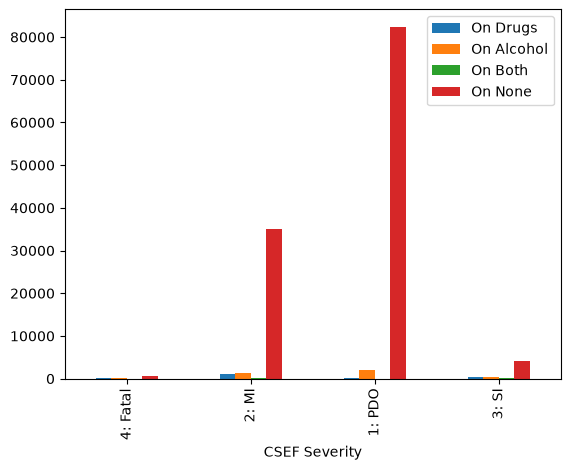

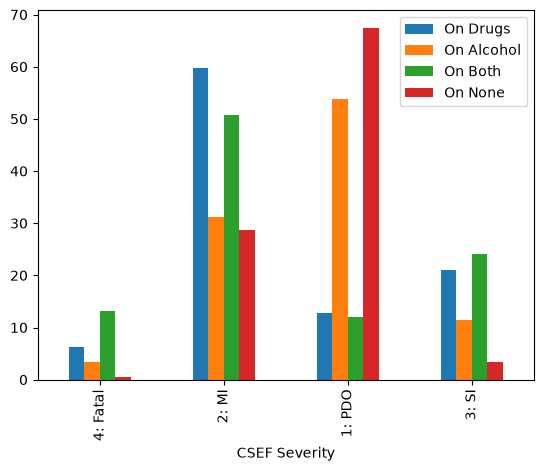

In [30]:
os.makedirs("figures", exist_ok=True)   # [MODIF] les PNG sont rangés dans figures/
pd_df.plot(kind='bar', x = 'CSEF Severity', )
plt.savefig('figures/severe.png')
pd_df_per.plot(kind='bar', x = 'CSEF Severity', )
plt.savefig('figures/severe_per.png')

Les graphiques de l'article sont difficiles à lire : niveaux de gravité dans un ordre aléatoire (celui des partitions),
effectifs d'échelles très différentes sur le même axe. Le scénario « ni alcool ni drogues » (≈ 122 000 accidents) écrase
les trois autres (quelques milliers). **[MODIF]** Voici une version améliorée des **pourcentages** : gravité dans l'ordre
croissant, une couleur par scénario (palette accessible), valeurs annotées.

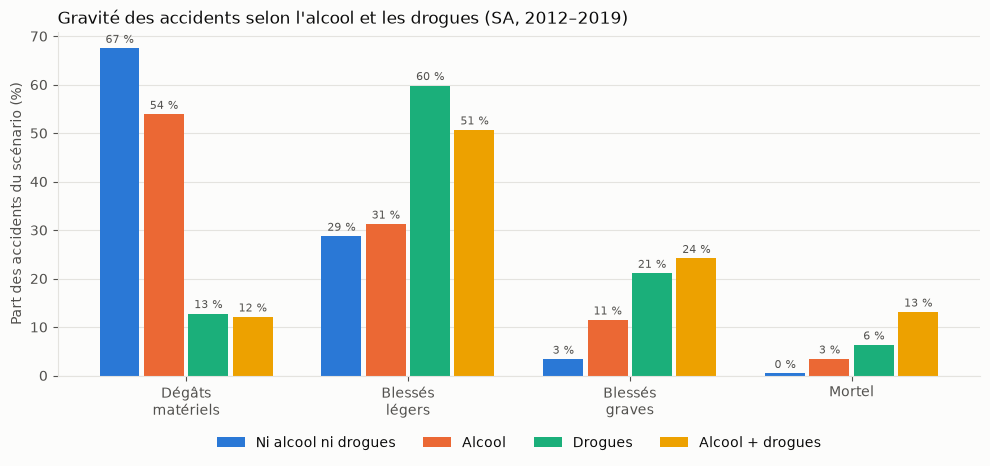

In [31]:
# [MODIF] Version lisible du graphique des pourcentages (même donnée que pd_df_per)
ORDRE_GRAVITE = ["1: PDO", "2: MI", "3: SI", "4: Fatal"]
LIBELLES_GRAVITE = ["Dégâts\nmatériels", "Blessés\nlégers", "Blessés\ngraves", "Mortel"]
SCENARIOS = {"On None": "Ni alcool ni drogues", "On Alcohol": "Alcool", "On Drugs": "Drogues", "On Both": "Alcool + drogues"}
# Palette catégorielle validée (ordre fixe), texte et grille en encre neutre
COULEURS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
ENCRE, ENCRE_2, GRILLE, FOND = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": FOND, "axes.facecolor": FOND, "axes.edgecolor": GRILLE,
                     "axes.labelcolor": ENCRE_2, "xtick.color": ENCRE_2, "ytick.color": ENCRE_2,
                     "text.color": ENCRE, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRILLE, "axes.axisbelow": True})

tab = pd_df_per.set_index("CSEF Severity").loc[ORDRE_GRAVITE, list(SCENARIOS)]
fig, ax = plt.subplots(figsize=(10, 4.8))
largeur = 0.2
for i, (cle, libelle) in enumerate(SCENARIOS.items()):
    x = [p + (i - 1.5) * largeur for p in range(len(ORDRE_GRAVITE))]
    barres = ax.bar(x, tab[cle], width=largeur - 0.02, color=COULEURS[i], label=libelle)
    ax.bar_label(barres, fmt="%.0f %%", fontsize=8, color=ENCRE_2, padding=2)
ax.set_xticks(range(len(ORDRE_GRAVITE)), LIBELLES_GRAVITE)
ax.set_ylabel("Part des accidents du scénario (%)")
ax.set_title("Gravité des accidents selon l'alcool et les drogues (SA, 2012–2019)", loc="left", fontsize=12)
ax.legend(frameon=False, ncols=4, loc="upper center", bbox_to_anchor=(0.5, -0.14))
fig.tight_layout()
fig.savefig("figures/gravite_alcool_drogues.png", dpi=120)
plt.show()

**Lecture.** Sans alcool ni drogues, 67,5 % des accidents ne causent que des dégâts matériels et seulement **3,8 %**
sont graves ou mortels (SI + Fatal). Avec de l'alcool, cette part monte à **14,9 %** (×4). Avec des drogues, elle
atteint **27,4 %** (×7), et **37,2 %** avec les deux (×10). La part d'accidents **mortels** passe de 0,42 % à 3,4 %
(alcool), 6,3 % (drogues) et 13,1 % (les deux). L'alcool et surtout les drogues sont donc associés à des accidents
nettement plus graves.

Deux réserves : les scénarios se recouvrent (« Alcool » inclut « Alcool + drogues »), et les contrôles sont
probablement plus systématiques après un accident grave. Les accidents matériels positifs sont sans doute
sous-détectés, ce qui gonfle mécaniquement la part des accidents graves dans les groupes « positifs ».

> **Amélioration possible** : les quatre tables sont calculées avec 4 filtres, 4 `groupBy`, 3 jointures et des **UDF
> Python**, qui obligent à faire passer les données dans un worker Python. La même table se calcule en **une seule
> passe**, avec des fonctions natives (`F.when`) et une fenêtre pour les pourcentages :

In [32]:
# [MODIF] Même table en une seule agrégation native (pas d'UDF, pas de jointure)
from pyspark.sql import Window
conditions = {
    "On Drugs":   col("Drugs Involved") == "Y",
    "On Alcohol": col("DUI Involved") == "Y",
    "On Both":    (col("DUI Involved") == "Y") & (col("Drugs Involved") == "Y"),
    "On None":    col("DUI Involved").isNull() & col("Drugs Involved").isNull(),
}
effectifs = (crash_df.groupBy("CSEF Severity")
             .agg(*[F.sum(F.when(c, 1).otherwise(0)).alias(k) for k, c in conditions.items()])
             .orderBy("CSEF Severity"))
toute_la_table = Window.partitionBy()   # 4 lignes : une fenêtre globale ne coûte rien ici
pourcentages = effectifs.select("CSEF Severity",
                                *[F.round(100 * col(k) / F.sum(k).over(toute_la_table), 2).alias(k) for k in conditions])
effectifs.show()
pourcentages.show()

+-------------+--------+----------+-------+-------+
|CSEF Severity|On Drugs|On Alcohol|On Both|On None|
+-------------+--------+----------+-------+-------+
|       1: PDO|     237|      2144|     36|  82430|
|        2: MI|    1109|      1243|    151|  35099|
|        3: SI|     391|       456|     72|   4100|
|     4: Fatal|     117|       136|     39|    508|
+-------------+--------+----------+-------+-------+



+-------------+--------+----------+-------+-------+
|CSEF Severity|On Drugs|On Alcohol|On Both|On None|
+-------------+--------+----------+-------+-------+
|       1: PDO|   12.78|     53.88|  12.08|  67.49|
|        2: MI|   59.82|     31.24|  50.67|  28.74|
|        3: SI|   21.09|     11.46|  24.16|   3.36|
|     4: Fatal|    6.31|      3.42|  13.09|   0.42|
+-------------+--------+----------+-------+-------+



## [Transformation] Mêmes requêtes en RDD, DataFrame et SparkSQL

Une même requête peut s'écrire avec les trois API de Spark :

* **RDD** : bas niveau. On manipule des listes Python et on gère soi-même le découpage et les index de colonnes.
  Spark ne peut pas optimiser.
* **DataFrame** : colonnes nommées et typées, requêtes optimisées par Catalyst.
* **SparkSQL** : le même moteur que les DataFrames, interrogé en SQL après avoir enregistré les DataFrames comme
  vues temporaires.

**Requête 1 : à Adélaïde, date et heure de l'accident, nombre de victimes de chaque unité, et sexe, âge et type de
permis du conducteur de l'unité.**

[MODIF] Pour les trois versions, l'article fait un `collect()` de plusieurs milliers de lignes. On garde le `collect()`,
mais on n'affiche que le nombre de lignes et les 5 premières.

In [33]:
# RDD Implementation
def parseKey(line):
    lines = line.split(',')
    array_line = []
    for value in lines:
        array_line.append(str(value).replace('"', ''))
    return (array_line[0], array_line[1:] )
units_rdd1 = units_rdd.map(parseKey)
crash_rdd1 = crash_rdd.map(parseKey)
joined_rdd = units_rdd1.join(crash_rdd1)
def parseRecord1(line):

    if line[1][1][1] == 'ADELAIDE':
        array_line = []
        array_line.append(line[1][1][1])
        array_line.append(line[1][0][7])
        array_line.append(line[1][0][8])
        array_line.append(line[1][0][11])
        array_line.append(line[1][1][12])
        array_line.append(line[1][1][6])
        array_line.append(line[1][1][9] + "-" + line[1][1][10] + "-" + line[1][1][11])
        return (array_line)

pharsed_rdd = joined_rdd.map(parseRecord1)
filtered_pharsed_rdd=pharsed_rdd.filter(lambda x: x is not None)
res_rdd_q1 = filtered_pharsed_rdd.collect()
print(len(res_rdd_q1), "lignes")   # [MODIF] affichage réduit
res_rdd_q1[:5]

11965 lignes


[['ADELAIDE', '018', 'SA', 'Unknown', '02:10 pm', '0', '2012-April-Friday'],
 ['ADELAIDE', 'XXX', '', '', '02:10 pm', '0', '2012-April-Friday'],
 ['ADELAIDE', '027', 'SA', 'Not Towing', '05:00 pm', '0', '2012-May-Friday'],
 ['ADELAIDE', '031', 'SA', 'Not Towing', '05:00 pm', '0', '2012-May-Friday'],
 ['ADELAIDE', '025', 'SA', 'Unknown', '08:00 pm', '0', '2012-June-Friday']]

In [34]:
# DataFrame implementation
joined_df = crash_df.join(units_df,crash_df.REPORT_ID==units_df.REPORT_ID, how='inner')
def find_date(d,m,y):
    return y + "-" + m + "-" + d

find_date_udf = udf(find_date)
joined_date_df = joined_df.withColumn('Date',find_date_udf('Day', 'Month', 'Year'))
joined_date_df = joined_date_df.filter(col("Suburb") == 'ADELAIDE')
res_df_q1 = joined_date_df.select('Date', 'Time', 'Total Cas', 'Sex', 'Age', 'Licence Type', 'Suburb').collect()
print(len(res_df_q1), "lignes")   # [MODIF] affichage réduit
res_df_q1[:5]

11965 lignes


[Row(Date='2012-January-Monday', Time='08:45 am', Total Cas=0, Sex='Male', Age='084', Licence Type='Full', Suburb='ADELAIDE'),
 Row(Date='2012-January-Monday', Time='08:45 am', Total Cas=0, Sex='Male', Age='040', Licence Type='Full', Suburb='ADELAIDE'),
 Row(Date='2012-January-Friday', Time='05:45 pm', Total Cas=0, Sex='Male', Age='047', Licence Type='Full', Suburb='ADELAIDE'),
 Row(Date='2012-January-Friday', Time='05:45 pm', Total Cas=0, Sex='Male', Age='XXX', Licence Type=None, Suburb='ADELAIDE'),
 Row(Date='2012-January-Friday', Time='07:30 pm', Total Cas=1, Sex='Female', Age='018', Licence Type='Provisional 2', Suburb='ADELAIDE')]

In [35]:
# SparkSQL implementation
units_df.createOrReplaceTempView("units_table")
crash_df.createOrReplaceTempView("crash_table")
joined_table = spark.sql('''
  SELECT (Year || '-' || Month || '-' || Day) as Date, Time, `Total Cas`, Sex, Age, `Licence Type`, Suburb
  FROM units_table u JOIN crash_table c
  ON u.REPORT_ID = c.REPORT_ID
  where c.Suburb == 'ADELAIDE'
''')
res_sql_q1 = joined_table.collect()
print(len(res_sql_q1), "lignes")   # [MODIF] affichage réduit
res_sql_q1[:5]

11965 lignes


[Row(Date='2012-January-Monday', Time='08:45 am', Total Cas=0, Sex='Male', Age='084', Licence Type='Full', Suburb='ADELAIDE'),
 Row(Date='2012-January-Monday', Time='08:45 am', Total Cas=0, Sex='Male', Age='040', Licence Type='Full', Suburb='ADELAIDE'),
 Row(Date='2012-January-Friday', Time='05:45 pm', Total Cas=0, Sex='Male', Age='047', Licence Type='Full', Suburb='ADELAIDE'),
 Row(Date='2012-January-Friday', Time='05:45 pm', Total Cas=0, Sex='Male', Age='XXX', Licence Type=None, Suburb='ADELAIDE'),
 Row(Date='2012-January-Friday', Time='07:30 pm', Total Cas=1, Sex='Female', Age='018', Licence Type='Provisional 2', Suburb='ADELAIDE')]

Les versions DataFrame et SQL renvoient le même nombre de lignes. **La version RDD ne renvoie pas les bonnes
colonnes** : elle affiche l'âge à la place du sexe, l'état du permis à la place de l'âge, l'attelage (`Towing`) à la
place du type de permis, et le nombre de **morts** à la place du nombre de victimes. Par ailleurs, `Total Cas` est le
nombre de victimes de l'**accident**, alors que la question porte sur les victimes de **chaque unité** (`No Of Cas`).
Détail et correction en section 10.

**Requête 2 : nombre total de victimes par quartier quand le véhicule était conduit par un conducteur sans permis.**

In [36]:
# RDD implementation
def parseKey(line):
    lines = line.split(',')
    array_line = []
    for value in lines:
        array_line.append(str(value).replace('"', ''))
    return (array_line[0], array_line[1:] )
units_rdd1 = units_rdd.map(parseKey)
crash_rdd1 = crash_rdd.map(parseKey)
joined_rdd = units_rdd1.join(crash_rdd1)
def parseRecord2(line):
    return (line[1][1][1], int(line[1][1][5]))

filtered_rdd = joined_rdd.filter(lambda x: (x[1][0][9] != "XX") & (x[1][0][8] != "UNKNOWN") & (x[1][0][10] != "Unknown") & (x[1][0][9] is not None) & (x[1][0][10] is not None) & (x[1][0][11] is not None))
pharased_filtered_rdd = filtered_rdd.map(parseRecord2)
result= pharased_filtered_rdd.groupByKey().mapValues(lambda x: sum(x))
res_rdd_q2 = result.collect()
print(len(res_rdd_q2), "quartiers ; ADELAIDE :", dict(res_rdd_q2).get("ADELAIDE"))   # [MODIF] affichage réduit
sorted(res_rdd_q2, key=lambda t: -t[1])[:5]

1633 quartiers ; ADELAIDE : 3935


[('NORWOOD', 5532),
 ('ADELAIDE', 3935),
 ('STEPNEY', 2186),
 ('PAYNEHAM', 2080),
 ('GLYNDE', 1806)]

In [37]:
# DataFrame implementation
joined_df = crash_df.join(units_df,crash_df.REPORT_ID==units_df.REPORT_ID, how='inner')
without_lic_df = joined_df.dropna(subset=('Licence Type','Licence Class', 'Lic State'), how='all')
by_suburb_no_lic_no_df = without_lic_df.filter((col('Licence Type') != 'Unknown') &(col('Licence Class') != 'XX') &(col('Lic State') != 'UNKNOWN')).groupby('Suburb').agg(F.count('No Of Cas').alias('Total casualty'))
res_df_q2 = by_suburb_no_lic_no_df.collect()
print(len(res_df_q2), "quartiers ; ADELAIDE :", {r[0]: r[1] for r in res_df_q2}.get("ADELAIDE"))   # [MODIF] affichage réduit
sorted(res_df_q2, key=lambda r: -r[1])[:5]

1608 quartiers ; ADELAIDE : 7514


[Row(Suburb='ADELAIDE', Total casualty=7514),
 Row(Suburb='PROSPECT', Total casualty=2448),
 Row(Suburb='NORTH ADELAIDE', Total casualty=2036),
 Row(Suburb='MAWSON LAKES', Total casualty=2027),
 Row(Suburb='NORWOOD', Total casualty=1951)]

In [38]:
# SparkSQL implementation
units_df.createOrReplaceTempView("units_table")
crash_df.createOrReplaceTempView("crash_table")
joined_table = spark.sql('''
  SELECT Suburb, COUNT(`Total Cas`)
  FROM units_table u JOIN crash_table c
  ON u.REPORT_ID = c.REPORT_ID
  WHERE `Lic State` IS NOT NULL and `Licence Class` IS NOT NULL and `Licence Type` IS NOT NULL and
  `Licence Type` != 'Unknown' and
  `Licence Class` != 'XX' and
  `Lic State` != 'UNKNOWN'
GROUP BY Suburb
''')
res_sql_q2 = joined_table.collect()
print(len(res_sql_q2), "quartiers ; ADELAIDE :", {r[0]: r[1] for r in res_sql_q2}.get("ADELAIDE"))   # [MODIF] affichage réduit
sorted(res_sql_q2, key=lambda r: -r[1])[:5]

1608 quartiers ; ADELAIDE : 7514


[Row(Suburb='ADELAIDE', count(Total Cas)=7514),
 Row(Suburb='PROSPECT', count(Total Cas)=2448),
 Row(Suburb='NORTH ADELAIDE', count(Total Cas)=2036),
 Row(Suburb='MAWSON LAKES', count(Total Cas)=2027),
 Row(Suburb='NORWOOD', count(Total Cas)=1951)]

Les trois versions **ne donnent pas le même résultat**, et aucune ne répond à la question. Pour Adélaïde, la
requête 4 de la section DataFrame donnait **43** victimes impliquant un conducteur sans permis. Ici, on obtient des
milliers :

* les filtres gardent les conducteurs dont le permis est **connu** (`!= 'Unknown'`, `!= 'XX'`…), c'est-à-dire surtout
  les conducteurs **avec** permis, au lieu de `Licence Type == 'Unlicenced'` ;
* la version RDD fait une **somme** de `Total Cas`, alors que les versions DataFrame et SQL font un **comptage** de lignes
  (`count`) ;
* la version RDD ne filtre pas les valeurs vides : `is not None` est toujours vrai sur une chaîne issue de `split`.
* la version RDD souffre aussi du `split(',')` (section 10.1). NORWOOD arrive en tête parce que son `LGA Name`
  (`"CC OF NORWOOD,PAYNEHAM & ST PETERS"`) contient une virgule : l'index 5 y lit `Total Units` au lieu de `Total Cas`.

Correction en section 10.

## [Prétraitement] Corrections des bugs de l'article

Cette section corrige les trois problèmes relevés, sans toucher au code d'origine ci-dessus.

### 10.1 Le `split(',')` casse les lignes dont un champ contient une virgule

Les fonctions RDD de l'article découpent chaque ligne avec `line.split(',')`. Or dans `crash_data`, certains champs entre
guillemets contiennent des virgules (`LGA Name` = `"CC OF NORWOOD,PAYNEHAM & ST PETERS"`, `"CITY OF PORT ADELAIDE ENFIELD"`…).
Sur ces lignes, toutes les colonnes situées après le champ fautif sont **décalées**. Combien de lignes sont concernées ?

In [39]:
nb_colonnes_crash = len(next(csv.reader([crash_header])))
nb_colonnes_units = len(next(csv.reader([units_header])))
crash_decalees = crash_rdd.filter(lambda l: len(l.split(',')) != nb_colonnes_crash).count()
units_decalees = units_rdd.filter(lambda l: len(l.split(',')) != nb_colonnes_units).count()
print(f"crash : {crash_decalees} lignes sur {crash_rdd.count()} mal découpées par split(',') "
      f"({100 * crash_decalees / crash_rdd.count():.1f} %)")
print(f"units : {units_decalees} lignes mal découpées")
print("Exemple :", crash_rdd.filter(lambda l: len(l.split(',')) != nb_colonnes_crash).first()[:120])

crash : 21379 lignes sur 127672 mal découpées par split(',') (16.7 %)
units : 0 lignes mal découpées


Exemple : "2012-1-21/08/2019","2 Metropolitan","STEPNEY","5069","CC OF NORWOOD,PAYNEHAM & ST PETERS",2,0,0,0,0,2012,"January","Sun


Environ **17 %** des accidents sont mal découpés : pour eux, `Year`, `Month`, `Day`, `Time`… sont faux dans la version RDD.
`units_data` n'est pas touché (aucune virgule dans les champs). La correction consiste à utiliser le module **`csv`**
de Python, qui respecte les guillemets, à la place de `split(',')` :

In [40]:
def parseKeyCsv(line):
    """Comme parseKey, mais découpe la ligne avec le module csv (respecte les guillemets)."""
    champs = next(csv.reader([line]))
    return (champs[0], champs[1:])

units_kv = units_rdd.map(parseKeyCsv)
crash_kv = crash_rdd.map(parseKeyCsv)
print("Colonnes par ligne (crash) :", crash_kv.map(lambda kv: len(kv[1]) + 1).distinct().collect())
print("Colonnes par ligne (units) :", units_kv.map(lambda kv: len(kv[1]) + 1).distinct().collect())

Colonnes par ligne (crash) : [33]


Colonnes par ligne (units) : [18]


Toutes les lignes ont maintenant 33 (crash) et 18 (units) colonnes.

### 10.2 Requête 1 : mauvais index dans `parseRecord1`

Après `parseKey`, la clé `REPORT_ID` est retirée : l'index `i` de la valeur correspond à la colonne `i + 1` du fichier.
Pour les unités, la colonne `Sex` (colonne 7) est donc à l'index **6**, `Age` à l'index **7** et `Licence Type` à
l'index **10**. L'article utilise 7, 8 et 11, décalés d'un cran. Côté accident, l'index 6 est `Total Fats` (morts), pas
`Total Cas`. On corrige les index, on lit le nombre de victimes **de l'unité** (`No Of Cas`), et on compare les trois API :

In [41]:
# Index des colonnes dans la valeur (en-tête sans REPORT_ID), au lieu de nombres "magiques"
U = {nom: i for i, nom in enumerate(next(csv.reader([units_header]))[1:])}
C = {nom: i for i, nom in enumerate(next(csv.reader([crash_header]))[1:])}

def ligne_adelaide(kv):
    unite, accident = kv[1]
    return (f"{accident[C['Year']]}-{accident[C['Month']]}-{accident[C['Day']]}", accident[C['Time']],
            unite[U['No Of Cas']], unite[U['Sex']], unite[U['Age']], unite[U['Licence Type']], accident[C['Suburb']])

q1_rdd = (units_kv.join(crash_kv)
          .filter(lambda kv: kv[1][1][C['Suburb']] == 'ADELAIDE')
          .map(ligne_adelaide))

colonnes_q1 = [F.concat_ws('-', 'Year', 'Month', 'Day').alias('Date'), 'Time', 'No Of Cas', 'Sex', 'Age', 'Licence Type', 'Suburb']
q1_df = (crash_df.join(units_df, 'REPORT_ID')          # jointure sur le nom : une seule colonne REPORT_ID
         .filter(col('Suburb') == 'ADELAIDE')
         .select(*colonnes_q1))                         # concat_ws natif au lieu de l'UDF find_date

q1_sql = spark.sql("""
  SELECT concat_ws('-', c.Year, c.Month, c.Day) AS Date, c.Time, u.`No Of Cas`, u.Sex, u.Age, u.`Licence Type`, c.Suburb
  FROM units_table u JOIN crash_table c ON u.REPORT_ID = c.REPORT_ID
  WHERE c.Suburb = 'ADELAIDE'
""")

def normalise(lignes):
    """Multiset de tuples, avec les NULL Spark rendus comme '' (valeur vide côté csv)."""
    from collections import Counter
    return Counter(tuple('' if v is None else str(v) for v in l) for l in lignes)

r_rdd, r_df, r_sql = normalise(q1_rdd.collect()), normalise(q1_df.collect()), normalise(q1_sql.collect())
print("Lignes : RDD =", sum(r_rdd.values()), "| DataFrame =", sum(r_df.values()), "| SQL =", sum(r_sql.values()))
print("RDD == DataFrame :", r_rdd == r_df, "| DataFrame == SQL :", r_df == r_sql)
q1_df.show(5)

Lignes : RDD = 11965 | DataFrame = 11965 | SQL = 11965
RDD == DataFrame : True | DataFrame == SQL : True


+-------------------+--------+---------+------+---+-------------+--------+
|               Date|    Time|No Of Cas|   Sex|Age| Licence Type|  Suburb|
+-------------------+--------+---------+------+---+-------------+--------+
|2012-January-Monday|08:45 am|        0|  Male|084|         Full|ADELAIDE|
|2012-January-Monday|08:45 am|        0|  Male|040|         Full|ADELAIDE|
|2012-January-Friday|05:45 pm|        0|  Male|047|         Full|ADELAIDE|
|2012-January-Friday|05:45 pm|        0|  Male|XXX|         NULL|ADELAIDE|
|2012-January-Friday|07:30 pm|        0|Female|018|Provisional 2|ADELAIDE|
+-------------------+--------+---------+------+---+-------------+--------+
only showing top 5 rows


Les trois implémentations renvoient maintenant **exactement les mêmes lignes** (comparaison en multiensemble).

### 10.3 Requête 2 : conducteurs sans permis

On filtre `Licence Type == 'Unlicenced'` et on **somme** `Total Cas`, avec la même définition que la requête 4 de la
section DataFrame :

In [42]:
q2_rdd = (units_kv.join(crash_kv)
          .filter(lambda kv: kv[1][0][U['Licence Type']] == 'Unlicenced')
          .map(lambda kv: (kv[1][1][C['Suburb']], int(kv[1][1][C['Total Cas']])))
          .reduceByKey(lambda a, b: a + b))            # reduceByKey : agrège avant le shuffle (mieux que groupByKey)

q2_df = (crash_df.join(units_df, 'REPORT_ID')
         .filter(col('Licence Type') == 'Unlicenced')
         .groupBy('Suburb').agg(F.sum('Total Cas').alias('Total casualty')))

q2_sql = spark.sql("""
  SELECT c.Suburb, SUM(c.`Total Cas`) AS `Total casualty`
  FROM units_table u JOIN crash_table c ON u.REPORT_ID = c.REPORT_ID
  WHERE u.`Licence Type` = 'Unlicenced'
  GROUP BY c.Suburb
""")

d_rdd = dict(q2_rdd.collect())
d_df = {r[0]: r[1] for r in q2_df.collect()}
d_sql = {r[0]: r[1] for r in q2_sql.collect()}
print("Quartiers : RDD =", len(d_rdd), "| DataFrame =", len(d_df), "| SQL =", len(d_sql))
print("Résultats identiques :", d_rdd == d_df == d_sql, "| ADELAIDE :", d_rdd["ADELAIDE"], d_df["ADELAIDE"], d_sql["ADELAIDE"])
q2_df.orderBy(col('Total casualty').desc(), 'Suburb').show(10)

Quartiers : RDD = 752 | DataFrame = 752 | SQL = 752
Résultats identiques : True | ADELAIDE : 43 43 43


+--------------+--------------+
|        Suburb|Total casualty|
+--------------+--------------+
|      ADELAIDE|            43|
|     SALISBURY|            30|
|      PROSPECT|            27|
|    INGLE FARM|            22|
| MORPHETT VALE|            20|
|SALISBURY EAST|            20|
|     DRY CREEK|            19|
| MURRAY BRIDGE|            19|
|  MAWSON LAKES|            17|
|NORTH ADELAIDE|            17|
+--------------+--------------+
only showing top 10 rows


Les trois API concordent et retrouvent bien les **43** victimes d'Adélaïde de la requête 4. Bilan de la Partie I :
l'API **RDD** est la plus fragile. Il faut découper soi-même les lignes et manipuler des index numériques, et c'est là
que se trouvent tous les bugs de l'article. Les API **DataFrame** et **SQL** s'appuient sur un lecteur CSV robuste et
des colonnes nommées, et Spark les optimise.

# Partie II — Analyse personnelle : qu'est-ce qui rend un accident grave ?

L'article ne regarde la gravité qu'au travers de l'alcool et des drogues, qui concernent moins de 4 % des accidents.
Je cherche ici les **autres facteurs** associés aux accidents **graves**, c'est-à-dire avec au moins un blessé grave ou
un mort (`CSEF Severity` ∈ {`3: SI`, `4: Fatal`}) : heure, jour, limitation de vitesse, usagers impliqués (moto, vélo,
piéton, poids lourd), âge du conducteur, conditions de route.

Démarche :

1. **[Prétraitement]** construire une table « un accident = une ligne » enrichie de variables dérivées des unités ;
2. **[EDA]** mesurer le **taux d'accidents graves** selon chaque facteur, toujours avec des agrégations Spark ;
3. **[Transformation] / [ML] / [Éval]** entraîner un classifieur Spark MLlib qui prédit si un accident sera grave à
   partir de ses circonstances, puis voir quelles variables il juge déterminantes.

## [Prétraitement] Construction d'une table « un accident = une ligne »

**Côté accidents** : on crée la cible `grave` (0/1), on extrait l'**heure** de `Time` (format `04:30 pm`), on convertit
la vitesse autorisée en entier et on code l'alcool et les drogues en 0/1. On utilise `try_cast`, qui renvoie `NULL` au
lieu d'échouer sur une valeur invalide : Spark 4 active le mode ANSI par défaut, et un `cast` classique y lève une erreur.

On **exclut** `Total Cas`, `Total Fats`, `Total SI` et `Total MI` des variables explicatives : ce sont des
**conséquences** de l'accident, qui définissent directement la gravité. Les garder serait une fuite de la cible
(*target leakage*).

In [43]:
heure_txt = col("Time")
heure_12 = F.expr("try_cast(substring(Time, 1, 2) AS INT)")
accidents = (crash_df
    .withColumn("grave", F.col("CSEF Severity").isin("3: SI", "4: Fatal").cast("int"))
    .withColumn("heure", (heure_12 % 12) + F.when(F.lower(F.substring(heure_txt, -2, 2)) == "pm", 12).otherwise(0))
    .withColumn("vitesse", F.expr("try_cast(`Area Speed` AS INT)"))
    .withColumn("nb_unites", F.expr("try_cast(`Total Units` AS INT)"))
    .withColumn("alcool", F.when(col("DUI Involved") == "Y", 1).otherwise(0))
    .withColumn("drogues", F.when(col("Drugs Involved") == "Y", 1).otherwise(0))
    .withColumn("annee", col("Year").cast("int")))

accidents.select("Time", "heure", "Area Speed", "vitesse", "CSEF Severity", "grave").show(5)
accidents.select(*[F.sum(col(c).isNull().cast("int")).alias(f"{c} NULL") for c in ["heure", "vitesse", "nb_unites"]]).show()

+--------+-----+----------+-------+-------------+-----+
|    Time|heure|Area Speed|vitesse|CSEF Severity|grave|
+--------+-----+----------+-------+-------------+-----+
|04:30 pm|   16|       060|     60|       1: PDO|    0|
|09:10 am|    9|       040|     40|       1: PDO|    0|
|11:30 am|   11|       100|    100|       1: PDO|    0|
|10:20 am|   10|       060|     60|       1: PDO|    0|
|03:30 pm|   15|       060|     60|       1: PDO|    0|
+--------+-----+----------+-------+-------------+-----+
only showing top 5 rows


+----------+------------+--------------+
|heure NULL|vitesse NULL|nb_unites NULL|
+----------+------------+--------------+
|         0|           0|             0|
+----------+------------+--------------+



**Côté unités** : on résume les 272 591 unités en **une ligne par accident** avec des indicateurs « au moins une unité
de ce type ». C'est un `groupBy("REPORT_ID")` suivi de `max` sur des 0/1, une agrégation typiquement distribuée.

In [44]:
age = F.expr("try_cast(Age AS INT)")
annee_veh = F.expr("try_cast(`Veh Year` AS INT)")
ut = col("Unit Type")
indicateurs = {
    "moto":            ut.isin("Motor Cycle", "Scooter"),
    "velo":            ut.isin("Pedal Cycle", "Power Asst. Bicycle"),
    "pieton":          ut.startswith("Pedestrian") | ut.isin("Motorised Wheelchair/Gopher", "Wheelchair / Elec. Wheelchair",
                                                             "Small Wheel Vehicle User"),
    "poids_lourd":     ut.isin("RIGID TRUCK LGE GE 4.5T", "SEMI TRAILER", "BDOUBLE - ROAD TRAIN", "OMNIBUS"),
    "obstacle_fixe":   ut.isin("Tree", "Stobie Pole", "Pole - not Stobie", "Other Fixed Obstruction", "Guard Rail",
                               "Sign Post", "Traffic Signal Pole", "Wire Rope Barrier", "Bridge"),
    "jeune_conducteur": col("Licence Type").isNotNull() & (age < 25),
    "conducteur_senior": col("Licence Type").isNotNull() & (age >= 70),
    "permis_probatoire": col("Licence Type").isin("Learners", "Provisional 1", "Provisional 2", "Probationary"),
    "sans_permis":     col("Licence Type").isin("Unlicenced", "Disqualified"),
    "vehicule_ancien": (annee_veh >= 1950) & (annee_veh < 2000),     # 1900 = valeur par défaut, exclue
    "tonneau":         col("Rollover") == "Y",
}
par_accident = units_df.groupBy("REPORT_ID").agg(
    *[F.max(F.when(cond, 1).otherwise(0)).alias(nom) for nom, cond in indicateurs.items()])

table = accidents.join(par_accident, "REPORT_ID", "left").na.fill(0, subset=list(indicateurs)).cache()
print(f"{table.count()} accidents, {len(table.columns)} colonnes")
table.select(*[F.round(100 * F.avg(c), 2).alias(c) for c in indicateurs]).show()

127672 accidents, 51 colonnes


+----+----+------+-----------+-------------+----------------+-----------------+-----------------+-----------+---------------+-------+
|moto|velo|pieton|poids_lourd|obstacle_fixe|jeune_conducteur|conducteur_senior|permis_probatoire|sans_permis|vehicule_ancien|tonneau|
+----+----+------+-----------+-------------+----------------+-----------------+-----------------+-----------+---------------+-------+
|5.53|5.55|  2.34|       8.69|        17.35|           32.15|            10.71|             9.34|       3.38|          34.43|   5.61|
+----+----+------+-----------+-------------+----------------+-----------------+-----------------+-----------+---------------+-------+



Chaque accident est conservé (127 672 lignes : jointure `left`, puis `0` si l'accident n'a pas d'unité du type). Le
tableau donne la part d'accidents impliquant chaque catégorie (en %). La table est mise en **cache** car elle est
réutilisée par toute la Partie II.

## [EDA] Facteurs de gravité

Fonction utilitaire : pour une ou plusieurs colonnes, on calcule dans Spark le nombre d'accidents et le **taux
d'accidents graves**. Seul le petit résultat agrégé passe ensuite par pandas pour l'affichage.

In [45]:
TAUX_GLOBAL = table.agg(F.avg("grave")).first()[0]
print(f"Taux global d'accidents graves (SI + Fatal) : {100 * TAUX_GLOBAL:.2f} % "
      f"({table.filter('grave = 1').count()} sur {table.count()})")

def taux_grave(*colonnes, min_accidents=0):
    return (table.groupBy(*colonnes)
            .agg(F.count("*").alias("accidents"), F.round(100 * F.avg("grave"), 2).alias("taux_grave_%"))
            .filter(col("accidents") >= min_accidents)
            .orderBy(*colonnes)
            .toPandas())

BLEU, GRIS = "#2a78d6", "#8a8984"

def barres_taux(ax, etiquettes, taux, titre, horizontal=False):
    """Barres du taux d'accidents graves + ligne de référence (taux global)."""
    if horizontal:
        b = ax.barh(etiquettes, taux, color=BLEU, height=0.7)
        ax.axvline(100 * TAUX_GLOBAL, color=GRIS, ls="--", lw=1)
        ax.grid(axis="x"); ax.grid(axis="y", visible=False)
        ax.set_xlabel("Accidents graves (%)")
    else:
        b = ax.bar(etiquettes, taux, color=BLEU, width=0.7)
        ax.axhline(100 * TAUX_GLOBAL, color=GRIS, ls="--", lw=1)
        ax.set_ylabel("Accidents graves (%)")
    ax.bar_label(b, fmt="%.1f", fontsize=8, color=ENCRE_2, padding=2)
    ax.set_title(titre, loc="left", fontsize=11)

Taux global d'accidents graves (SI + Fatal) : 4.38 % (5597 sur 127672)


### Heure de la journée

Deux mesures d'échelles différentes, le **nombre** d'accidents et le **taux** de gravité, sont tracées dans deux
graphiques superposés plutôt que sur un double axe.

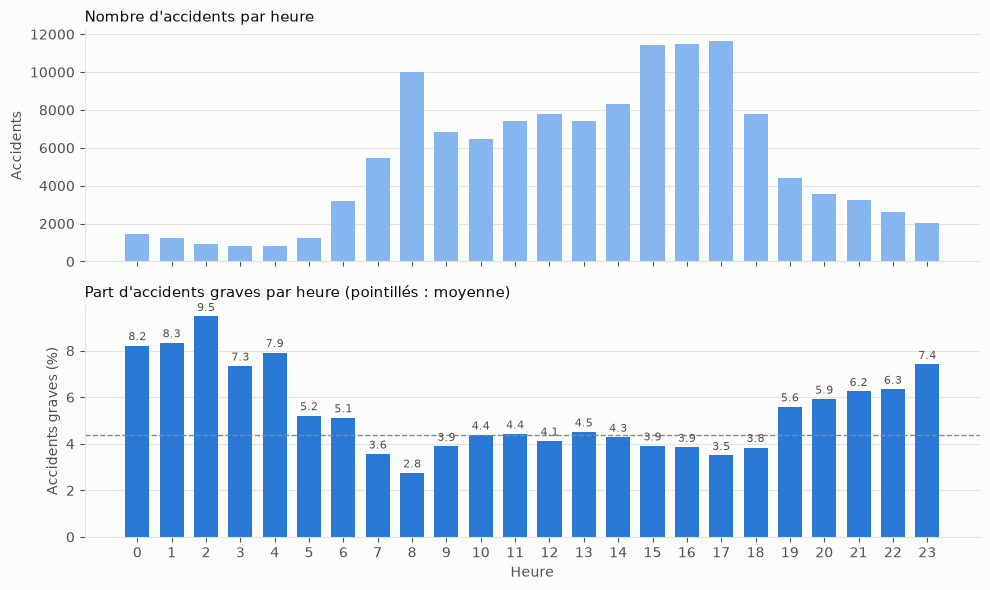

heure,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
accidents,1460.00,1235.00,940.00,831.00,808.00,1247.00,3186.00,5484.00,10026.00,6833.00,...,8304.00,11441.00,11492.00,11642.0,7790.00,4400.00,3582.00,3248.00,2586.00,2037.00
taux_grave_%,8.22,8.34,9.47,7.34,7.92,5.21,5.12,3.56,2.75,3.89,...,4.28,3.91,3.85,3.5,3.84,5.59,5.92,6.25,6.34,7.41


In [46]:
par_heure = taux_grave("heure")
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax1.bar(par_heure["heure"], par_heure["accidents"], color="#86b6ef", width=0.7)
ax1.set_ylabel("Accidents"); ax1.set_title("Nombre d'accidents par heure", loc="left", fontsize=11)
barres_taux(ax2, par_heure["heure"], par_heure["taux_grave_%"], "Part d'accidents graves par heure (pointillés : moyenne)")
ax2.set_xticks(range(24)); ax2.set_xlabel("Heure")
fig.tight_layout(); fig.savefig("figures/gravite_par_heure.png", dpi=120); plt.show()
par_heure.set_index("heure").T

Les accidents sont surtout **nombreux** aux heures de pointe (8 h et 15–17 h, plus de 10 000 accidents par heure), mais
ce sont les accidents de **nuit** qui sont les plus **graves**. Entre minuit et 5 h, le taux de gravité atteint 7 à 9,5 %,
soit environ **deux fois la moyenne** (4,4 %) et trois fois celui de 8 h (2,75 %). La nuit, il y a moins de trafic, mais
plus de vitesse, de fatigue et d'alcool, et davantage d'accidents à un seul véhicule. Volume et gravité ne vont pas de
pair.

### Jour de la semaine et jour/nuit

jour,Lun,Mar,Mer,Jeu,Ven,Sam,Dim
accidents,17681.00,19317.00,20159.00,20799.00,21249.00,15693.00,12774.00
taux_grave_%,4.09,3.89,3.83,3.76,4.19,5.53,6.33


,DayNight,accidents,taux_grave_%
0,Daylight,98724,3.94
1,Night,28948,5.90


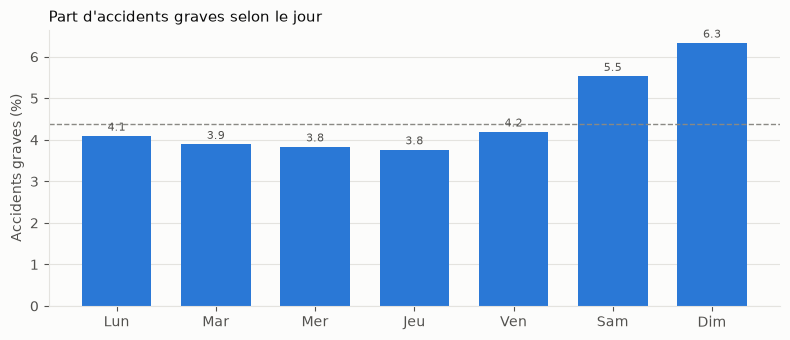

In [47]:
JOURS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
JOURS_FR = ["Lun", "Mar", "Mer", "Jeu", "Ven", "Sam", "Dim"]
par_jour = taux_grave("Day").set_index("Day").loc[JOURS]
par_dn = taux_grave("DayNight")
display(par_jour.assign(jour=JOURS_FR).set_index("jour").T, par_dn)

fig, ax = plt.subplots(figsize=(8, 3.5))
barres_taux(ax, JOURS_FR, par_jour["taux_grave_%"], "Part d'accidents graves selon le jour")
fig.tight_layout(); fig.savefig("figures/gravite_par_jour.png", dpi=120); plt.show()

Le **week-end** compte moins d'accidents, mais ils sont plus graves : 5,5 % le samedi et 6,3 % le dimanche, contre
3,8–4,2 % en semaine. C'est cohérent avec plus de déplacements de loisirs, de trajets ruraux et de conduite de nuit. Un
accident de nuit est grave dans 5,9 % des cas, contre 3,9 % de jour, soit 1,5 fois plus.

### Limitation de vitesse

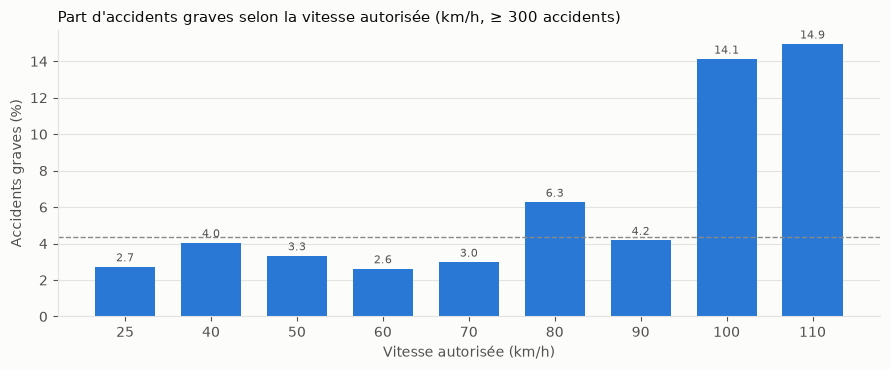

,0,1,2,3,4,5,6,7,8
vitesse,25.00,40.00,50.00,60.00,70.00,80.00,90.00,100.00,110.00
accidents,476.00,1852.00,34244.00,61035.00,4026.00,11013.00,2106.00,7413.00,5359.00
taux_grave_%,2.73,4.05,3.33,2.62,2.98,6.27,4.18,14.12,14.95


In [48]:
par_vitesse = taux_grave("vitesse", min_accidents=300)
fig, ax = plt.subplots(figsize=(9, 3.8))
barres_taux(ax, par_vitesse["vitesse"].astype(str), par_vitesse["taux_grave_%"],
            "Part d'accidents graves selon la vitesse autorisée (km/h, ≥ 300 accidents)")
ax.set_xlabel("Vitesse autorisée (km/h)")
fig.tight_layout(); fig.savefig("figures/gravite_par_vitesse.png", dpi=120); plt.show()
par_vitesse.T

C'est le facteur le plus net : le taux d'accidents graves **augmente fortement avec la vitesse autorisée**. Il est
d'environ 3 % en zone 50–60 km/h (où ont lieu 75 % des accidents), de 6 % à 80 km/h, et dépasse **14 %** sur les routes
à 100–110 km/h, soit 5 fois plus qu'en ville. L'énergie d'un choc croît avec le
carré de la vitesse. En ville, il y a beaucoup d'accidents, mais surtout matériels. Sur route, il y en a peu, mais ils
sont graves.

### Usagers et conducteurs impliqués

Pour chaque indicateur, on compare le taux d'accidents graves quand il est présent avec la moyenne générale :

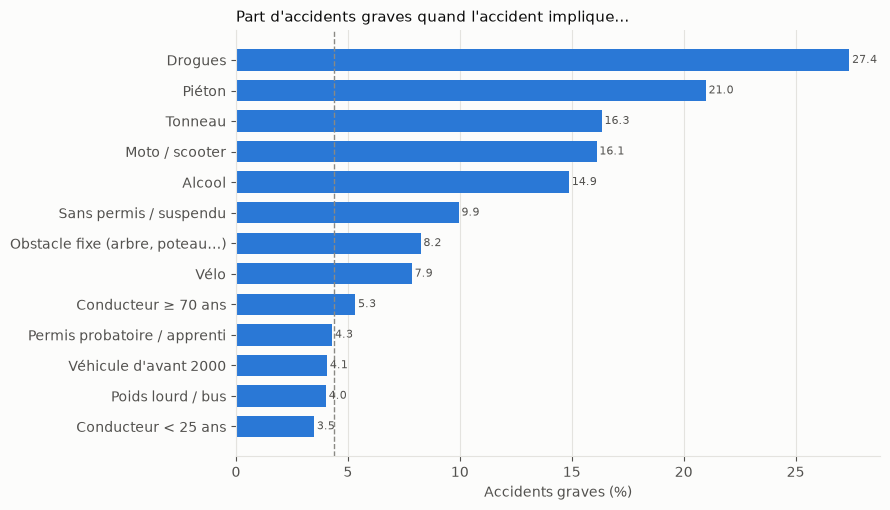

,facteur,accidents,taux_grave_%,risque_relatif
0,Drogues,1854,27.40,6.3
1,Piéton,2983,20.99,4.8
2,Tonneau,7167,16.34,3.7
3,Moto / scooter,7057,16.11,3.7
4,Alcool,3979,14.88,3.4
5,Sans permis / suspendu,4310,9.95,2.3
6,"Obstacle fixe (arbre, poteau…)",22151,8.25,1.9
7,Vélo,7083,7.86,1.8
8,Conducteur ≥ 70 ans,13680,5.33,1.2
9,Permis probatoire / apprenti,11920,4.30,1.0


In [49]:
facteurs = list(indicateurs) + ["alcool", "drogues"]
LIBELLES = {"moto": "Moto / scooter", "velo": "Vélo", "pieton": "Piéton", "poids_lourd": "Poids lourd / bus",
            "obstacle_fixe": "Obstacle fixe (arbre, poteau…)", "jeune_conducteur": "Conducteur < 25 ans",
            "conducteur_senior": "Conducteur ≥ 70 ans", "permis_probatoire": "Permis probatoire / apprenti",
            "sans_permis": "Sans permis / suspendu", "vehicule_ancien": "Véhicule d'avant 2000",
            "tonneau": "Tonneau", "alcool": "Alcool", "drogues": "Drogues"}
lignes = table.agg(*[F.sum(c).alias(f"n_{c}") for c in facteurs],
                   *[F.avg(F.when(col(c) == 1, col("grave"))).alias(f"t_{c}") for c in facteurs]).first()
par_facteur = (pd.DataFrame({"facteur": [LIBELLES[c] for c in facteurs],
                             "accidents": [lignes[f"n_{c}"] for c in facteurs],
                             "taux_grave_%": [round(100 * lignes[f"t_{c}"], 2) for c in facteurs]})
               .assign(risque_relatif=lambda d: (d["taux_grave_%"] / (100 * TAUX_GLOBAL)).round(1))
               .sort_values("taux_grave_%"))

fig, ax = plt.subplots(figsize=(9, 5.2))
barres_taux(ax, par_facteur["facteur"], par_facteur["taux_grave_%"],
            "Part d'accidents graves quand l'accident implique…", horizontal=True)
fig.tight_layout(); fig.savefig("figures/gravite_par_usager.png", dpi=120); plt.show()
par_facteur.sort_values("taux_grave_%", ascending=False).reset_index(drop=True)

Le `risque_relatif` est le taux de l'accident rapporté au taux moyen. En tête viennent les **drogues** (27 %, ×6,3) et
les **usagers vulnérables** : un accident impliquant un **piéton** est grave dans 21 % des cas (×4,8), et une **moto**
dans 16 % (×3,7). Suivent les **tonneaux** (×3,7), l'**alcool** (×3,4), les conducteurs **sans permis** (×2,3), les
**obstacles fixes** (×1,9) et les **vélos** (×1,8).

À l'inverse, les **jeunes conducteurs** (< 25 ans, ×0,8), les **permis probatoires** (×1,0), les **poids lourds** et les
**véhicules anciens** (×0,9) ne rendent pas les accidents plus graves. Ces groupes ont **beaucoup** d'accidents (un
accident sur trois implique un conducteur de moins de 25 ans), mais surtout des accidents matériels. Les conducteurs de
70 ans et plus sont légèrement au-dessus de la moyenne (×1,2), ce qui reflète sans doute leur plus grande fragilité
physique.

### Conditions de route et zone

In [50]:
conditions_route = ["Stats Area", "Weather Cond", "Moisture Cond", "Road Surface", "Horizontal Align", "Vertical Align"]
resume = pd.concat([taux_grave(c, min_accidents=300).rename(columns={c: "valeur"}).assign(variable=c)
                    for c in conditions_route])[["variable", "valeur", "accidents", "taux_grave_%"]]
resume.reset_index(drop=True)

,variable,valeur,accidents,taux_grave_%
0,Stats Area,1 City,6940,2.65
1,Stats Area,2 Metropolitan,100817,3.07
2,Stats Area,3 Country,19915,11.62
3,Weather Cond,Not Raining,115956,4.44
4,Weather Cond,Raining,11268,3.75
5,Weather Cond,Unknown,448,6.70
6,Moisture Cond,Dry,111103,4.46
7,Moisture Cond,Wet,16321,3.82
8,Road Surface,Sealed,124151,4.12
9,Road Surface,Unsealed,3507,13.69


* **Zone** : un accident à la **campagne** (`3 Country`) est 3 à 4 fois plus souvent grave qu'en métropole, ce qui
  rejoint l'effet de la vitesse.
* **Tracé** : en **virage**, surtout à visibilité réduite, et sur **route non goudronnée**, la gravité est bien plus forte.
* **Pluie / route mouillée** : contre-intuitivement, la gravité est *plus faible* par temps de pluie. On roule plus
  prudemment, et une chaussée mouillée produit surtout des accrochages urbains (collisions par l'arrière).

Ces facteurs sont **corrélés** entre eux : la campagne va avec la vitesse élevée, les virages et les routes non
goudronnées. Pour démêler leurs effets, on passe à un modèle multivarié.

## [Transformation] Pipeline de features Spark ML

Variables explicatives, toutes connues au moment de l'accident :

* **catégorielles** : jour, jour/nuit, météo, humidité, revêtement, tracé horizontal et vertical, zone, type de position
  (carrefour…), signalisation, **type d'accident**, tranche horaire ;
* **numériques / binaires** : vitesse autorisée, nombre d'unités, alcool, drogues et les 11 indicateurs issus des unités.

Le `Pipeline` Spark enchaîne `StringIndexer` (catégorie → indice), `OneHotEncoder` (indice → vecteur creux) et
`VectorAssembler` (tout → un vecteur `features`). Au préalable, les modalités qui comptent moins de 300 accidents sont
regroupées en « Autre » : un passage à niveau sans signalisation (6 accidents) ne suffit pas à estimer un effet fiable.

**Déséquilibre des classes** : seuls ~4,4 % des accidents sont graves. Un modèle qui prédit toujours « non grave »
aurait 95,6 % d'exactitude, mais serait inutile. On ajoute donc un **poids** par ligne, inverse de la fréquence de sa
classe (`weightCol`), et on évaluera avec l'**AUC** plutôt que l'exactitude.

In [51]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator

modele_df = (table
    .withColumn("tranche_horaire", F.when(col("heure") < 6, "0-5h").when(col("heure") < 10, "6-9h")
                                   .when(col("heure") < 16, "10-15h").when(col("heure") < 20, "16-19h").otherwise("20-23h"))
    .na.fill({"vitesse": 60, "nb_unites": 2})        # quelques valeurs manquantes -> valeur la plus fréquente
    .withColumn("vitesse", col("vitesse").cast("double"))
    .withColumn("nb_unites", col("nb_unites").cast("double")))

CATEGORIELLES = ["Day", "DayNight", "Weather Cond", "Moisture Cond", "Road Surface", "Horizontal Align",
                 "Vertical Align", "Stats Area", "Position Type", "Traffic Ctrls", "Crash Type", "tranche_horaire"]
NUMERIQUES = ["vitesse", "nb_unites", "alcool", "drogues"] + list(indicateurs)

# Modalités rares (< 300 accidents, ex. « Rail Xing - No Control » : 6 accidents) regroupées en « Autre » :
# sinon le modèle leur attribue des coefficients extrêmes et instables, appris sur une poignée de lignes
SEUIL_RARE = 300
for c in CATEGORIELLES:
    frequentes = [r[0] for r in modele_df.groupBy(c).count().filter(col("count") >= SEUIL_RARE).collect()]
    modele_df = modele_df.withColumn(c, F.when(col(c).isin(frequentes), col(c)).otherwise("Autre"))

# Découpage apprentissage / test (80/20, graine fixe pour la reproductibilité)
train, test = modele_df.randomSplit([0.8, 0.2], seed=42)
p_grave = train.agg(F.avg("grave")).first()[0]
poids = {1: 0.5 / p_grave, 0: 0.5 / (1 - p_grave)}
train = train.withColumn("poids", F.when(col("grave") == 1, poids[1]).otherwise(poids[0])).cache()
test = test.cache()
print(f"Apprentissage : {train.count()} accidents ({100 * p_grave:.2f} % graves) | Test : {test.count()}")
print(f"Poids : grave = {poids[1]:.2f}, non grave = {poids[0]:.3f}")

preparation = [
    StringIndexer(inputCols=CATEGORIELLES, outputCols=[f"{c}_idx" for c in CATEGORIELLES], handleInvalid="keep"),
    OneHotEncoder(inputCols=[f"{c}_idx" for c in CATEGORIELLES], outputCols=[f"{c}_ohe" for c in CATEGORIELLES]),
    VectorAssembler(inputCols=[f"{c}_ohe" for c in CATEGORIELLES] + NUMERIQUES, outputCol="features"),
]

Apprentissage : 102338 accidents (4.36 % graves) | Test : 25334
Poids : grave = 11.47, non grave = 0.523


## [ML] Régression logistique et forêt aléatoire

Deux modèles complémentaires :

* **Régression logistique** (avec une légère régularisation L2) : modèle linéaire, **interprétable** par ses coefficients
  (rapports de cotes) ;
* **Forêt aléatoire** (100 arbres, profondeur 8) : capte les interactions non linéaires (vitesse × zone, moto × virage…)
  et fournit une **importance** des variables.

Le split et les poids sont les mêmes pour les deux modèles. Tout le calcul (indexation, encodage, apprentissage) est
distribué par Spark.

In [52]:
t0 = time.perf_counter()
pipeline_lr = Pipeline(stages=preparation + [
    LogisticRegression(featuresCol="features", labelCol="grave", weightCol="poids", maxIter=100, regParam=0.001)])
modele_lr = pipeline_lr.fit(train)
print(f"Régression logistique entraînée en {time.perf_counter() - t0:.1f} s")

t0 = time.perf_counter()
pipeline_rf = Pipeline(stages=preparation + [
    RandomForestClassifier(featuresCol="features", labelCol="grave", weightCol="poids",
                           numTrees=100, maxDepth=8, seed=42)])
modele_rf = pipeline_rf.fit(train)
print(f"Forêt aléatoire entraînée en {time.perf_counter() - t0:.1f} s")

Régression logistique entraînée en 17.8 s


Forêt aléatoire entraînée en 23.5 s


## [Éval] Évaluation sur le jeu de test

Métriques, calculées sur les 20 % d'accidents jamais vus à l'apprentissage :

* **AUC ROC** : probabilité qu'un accident grave tiré au hasard reçoive un score plus élevé qu'un accident non grave
  (0,5 = hasard, 1 = parfait) ;
* **AUC PR** (précision-rappel) : plus exigeante quand la classe positive est rare. Le hasard vaut ici le taux de base,
  ~0,044 ;
* au seuil de 0,5 : **matrice de confusion**, **rappel** (part des accidents graves détectés) et **précision** (part des
  alertes justifiées).

In [53]:
eval_roc = BinaryClassificationEvaluator(labelCol="grave", rawPredictionCol="rawPrediction", metricName="areaUnderROC")
eval_pr = BinaryClassificationEvaluator(labelCol="grave", rawPredictionCol="rawPrediction", metricName="areaUnderPR")

def evaluer(nom, modele):
    pred = modele.transform(test).cache()
    m = pred.groupBy("grave", "prediction").count().toPandas()
    n = lambda g, p: int(m[(m.grave == g) & (m.prediction == p)]["count"].sum())
    vp, fn, fp, vn = n(1, 1.0), n(1, 0.0), n(0, 1.0), n(0, 0.0)
    res = {"modèle": nom, "AUC ROC": round(eval_roc.evaluate(pred), 4), "AUC PR": round(eval_pr.evaluate(pred), 4),
           "rappel": round(vp / (vp + fn), 3), "précision": round(vp / (vp + fp), 3),
           "exactitude": round((vp + vn) / (vp + vn + fp + fn), 3), "VP": vp, "FN": fn, "FP": fp, "VN": vn}
    pred.unpersist()
    return res

taux_test = test.agg(F.avg("grave")).first()[0]
resultats = pd.DataFrame([
    {"modèle": "Référence : toujours « non grave »", "AUC ROC": 0.5, "AUC PR": round(taux_test, 4), "rappel": 0.0,
     "précision": float("nan"), "exactitude": round(1 - taux_test, 3)},
    evaluer("Régression logistique", modele_lr),
    evaluer("Forêt aléatoire", modele_rf),
]).set_index("modèle")
resultats

,AUC ROC,AUC PR,rappel,précision,exactitude,VP,FN,FP,VN
modèle,,,,,,,,,
Référence : toujours « non grave »,0.5000,0.0448,0.000,NaN,0.955,NaN,NaN,NaN,NaN
Régression logistique,0.8582,0.2607,0.773,0.142,0.781,878.0,258.0,5286.0,18912.0
Forêt aléatoire,0.8383,0.2117,0.724,0.148,0.801,823.0,313.0,4720.0,19478.0


Les deux modèles font **beaucoup mieux que le hasard**. La **régression logistique** est la meilleure : AUC ROC de
**0,86** et AUC PR de 0,26, soit près de 6 fois le hasard (0,045). La forêt aléatoire suit (0,84 / 0,21) : les effets
sont en grande partie additifs, et un modèle linéaire suffit.

Le modèle de référence a la meilleure *exactitude* (95,5 %), mais ne détecte aucun accident grave : c'est pour cela
qu'on ne juge pas sur l'exactitude. Avec la pondération, la régression logistique détecte **77 % des accidents
graves** (rappel), au prix de nombreuses fausses alertes (précision de 14 %). C'est attendu quand on cherche une classe rare à partir des seules circonstances de l'accident : la gravité
dépend aussi de facteurs absents des données (ceinture, vitesse réelle, état du véhicule, secours…).

### Interprétation

**Régression logistique** : un coefficient positif augmente la probabilité d'accident grave, et `exp(coef)` est le
**rapport de cotes** (*odds ratio*) toutes choses égales par ailleurs. Les noms des variables viennent des métadonnées
du vecteur `features`.

In [54]:
import numpy as np

def noms_features(modele, df):
    """Nom de chaque composante du vecteur features (métadonnées ML attachées par le VectorAssembler)."""
    meta = modele.transform(df.limit(1)).schema["features"].metadata["ml_attr"]["attrs"]
    noms = {}
    for groupe in meta.values():
        for a in groupe:
            noms[a["idx"]] = a["name"].replace("_ohe_", " = ")
    return [noms[i] for i in range(len(noms))]

noms = noms_features(modele_lr, test)
coefs = modele_lr.stages[-1].coefficients.toArray()
lr_coefs = (pd.DataFrame({"variable": noms, "coef": coefs, "rapport_de_cotes": np.exp(coefs)})
            .sort_values("coef"))
print("Les 12 variables qui AUGMENTENT le plus la probabilité d'accident grave :")
display(lr_coefs.tail(12).iloc[::-1].round(2).reset_index(drop=True))
print("Les 8 variables qui la DIMINUENT le plus :")
display(lr_coefs.head(8).round(2).reset_index(drop=True))

Les 12 variables qui AUGMENTENT le plus la probabilité d'accident grave :


,variable,coef,rapport_de_cotes
0,pieton,2.36,10.62
1,velo,2.17,8.79
2,moto,2.16,8.64
3,drogues,1.74,5.68
4,Crash Type = Head On,1.45,4.28
5,Crash Type = Other,1.02,2.76
6,tonneau,0.92,2.52
7,alcool,0.86,2.37
8,conducteur_senior,0.84,2.32
9,Crash Type = Hit Pedestrian,0.84,2.32


Les 8 variables qui la DIMINUENT le plus :


,variable,coef,rapport_de_cotes
0,Crash Type = Hit Animal,-1.31,0.27
1,Traffic Ctrls = Autre,-1.27,0.28
2,Traffic Ctrls = Roundabout,-0.73,0.48
3,Position Type = Pedestrian Crossing,-0.68,0.51
4,Crash Type = Side Swipe,-0.67,0.51
5,Crash Type = Rear End,-0.66,0.52
6,Stats Area = 1 City,-0.52,0.59
7,Vertical Align = Unknown,-0.36,0.70


**Forêt aléatoire** : l'importance de chaque variable d'origine est la somme des importances de ses modalités
encodées en *one-hot*.

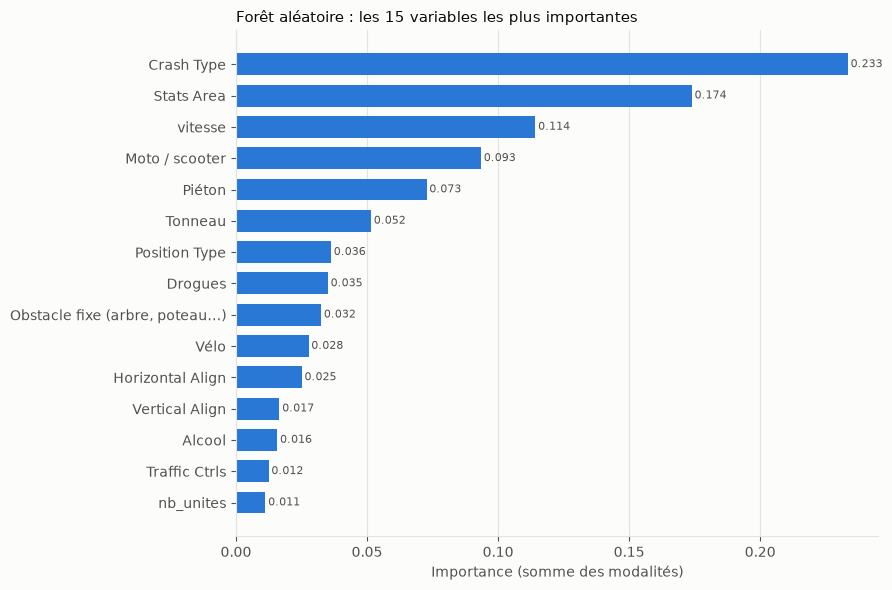

,importance
Crash Type,0.233
Stats Area,0.174
vitesse,0.114
Moto / scooter,0.093
Piéton,0.073
Tonneau,0.052
Position Type,0.036
Drogues,0.035
"Obstacle fixe (arbre, poteau…)",0.032
Vélo,0.028


In [55]:
imp = modele_rf.stages[-1].featureImportances.toArray()
noms_rf = noms_features(modele_rf, test)
importance = (pd.DataFrame({"variable": [n.split(" = ")[0] for n in noms_rf], "importance": imp})
              .groupby("variable")["importance"].sum().sort_values())
importance.index = [LIBELLES.get(v, v) for v in importance.index]

fig, ax = plt.subplots(figsize=(9, 6))
b = ax.barh(importance.index[-15:], importance.values[-15:], color=BLEU, height=0.7)
ax.bar_label(b, fmt="%.3f", fontsize=8, color=ENCRE_2, padding=2)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("Importance (somme des modalités)")
ax.set_title("Forêt aléatoire : les 15 variables les plus importantes", loc="left", fontsize=11)
fig.tight_layout(); fig.savefig("figures/importance_variables.png", dpi=120); plt.show()
importance.sort_values(ascending=False).head(10).round(3).to_frame("importance")

Les deux modèles s'accordent sur l'essentiel, ce qui confirme l'analyse exploratoire :

1. **Le type d'accident** est la variable la plus importante pour la forêt (0,23). Pour la régression logistique, un
   choc frontal multiplie la cote d'accident grave par 4,3 et un piéton renversé par 2,3. Collisions par l'arrière,
   accrochages latéraux et chocs avec un animal la divisent par 2 à 4.
2. **La zone et la vitesse autorisée** viennent ensuite pour la forêt (0,17 et 0,11). Elles n'apparaissent pas dans
   le top des coefficients logistiques uniquement parce que la vitesse y compte **par km/h**. À l'inverse, un accident
   en centre-ville (`1 City`) a une cote divisée par 1,7.
3. **Les usagers vulnérables** : à circonstances égales, la présence d'un **piéton** multiplie la cote par 10,6, celle
   d'un **vélo** par 8,8 et celle d'une **moto** par 8,6. Ce sont les plus forts effets du modèle.
4. **Les drogues** (×5,7) et **l'alcool** (×2,4) gardent un effet propre, même une fois le type d'accident, la
   vitesse et l'heure pris en compte.
5. **Un conducteur de 70 ans ou plus** multiplie la cote par 2,3 à circonstances égales. Ses accidents ne sont pas
   plus violents, mais les personnes âgées sont plus fragiles.

À l'inverse, la tranche horaire, le jour, la météo et la présence d'un jeune conducteur n'apparaissent pas parmi les
variables importantes. Leur effet brut (nuit, week-end) s'explique en grande partie par les autres variables : routes
rapides, accidents à un seul véhicule, alcool.

## [Conclusion]

**Partie I — reproduction.** Le notebook de l'article a été reproduit intégralement avec PySpark 4.2 sous Windows. Les
résultats affichés dans l'article sont retrouvés à l'identique (partitions, âges moyens, morts par type d'accident,
gravité selon l'alcool et les drogues, victimes des conducteurs sans permis). Cette reproduction a aussi révélé :

* des obstacles propres à Windows (listage de dossier par Hadoop, plantage de `take()`, workers Python qui meurent
  par intermittence pendant les jointures RDD), contournés sans modifier la logique. Le dernier est réglé en
  autorisant Spark à **recalculer** une tâche échouée (`local[*,4]`) : c'est la résilience des RDD mise en pratique.
  Lors de l'exécution finale, 4 tâches ont échoué puis ont été recalculées automatiquement ;
* trois **bugs** dans le code de l'article, tous dans la partie **RDD** ou dans les requêtes « trois API » :
  `split(',')` qui casse 17 % des lignes d'accidents, des index de colonnes décalés, et une requête « sans permis » qui
  sélectionne en réalité les conducteurs avec permis. Une fois corrigées, les trois API (RDD, DataFrame, SQL) donnent
  **exactement** les mêmes résultats.

Leçon pratique : l'API RDD oblige à gérer soi-même le format et les positions des colonnes, ce qui est une source
d'erreurs. Les DataFrames et SparkSQL sont plus sûrs (colonnes nommées, lecteur CSV robuste) et optimisés par Spark.

**Partie II — analyse personnelle.** Sur 127 672 accidents, 4,4 % sont graves (blessé grave ou mort). Ce qui rend un
accident grave, ce n'est pas tant le nombre d'accidents d'un contexte que **l'énergie du choc et la vulnérabilité des
personnes** : vitesse autorisée élevée et zone rurale (taux de gravité ×5 entre 50 et 110 km/h), usagers sans
carrosserie (piéton, vélo, moto), chocs frontaux, tonneaux et obstacles fixes, alcool et drogues, et conducteurs âgés.
Les heures de pointe, les zones urbaines et les jeunes conducteurs concentrent les accidents, mais surtout des
accidents matériels. Une régression logistique Spark MLlib entraînée sur ces seules circonstances classe correctement
un accident grave et un accident bénin dans **86 %** des paires (AUC ROC = 0,86), et détecte 77 % des accidents graves.

**Limites et pistes** : ce sont des corrélations, pas des causes (biais de contrôle pour l'alcool et les drogues,
facteurs absents des données). On pourrait ajouter les autres tables du DPTI (*Casualties*), le volume de trafic par
route pour passer d'un taux de gravité à un vrai **risque par kilomètre parcouru**, ou une validation croisée
(`CrossValidator`) pour régler les hyperparamètres.

In [56]:
print(f"Durée totale d'exécution du notebook : {(time.perf_counter() - T0_NOTEBOOK) / 60:.1f} min")
spark.stop()

Durée totale d'exécution du notebook : 11.2 min
